# <div align="center"> Model of fatty acid de novo synthesis

<img src="FADNS_simple.svg" width=1200 height=600/>

In this part we investigate the search of parameters to reproduce the data from _Topolska et al. 2020_.

We consider the simple description of the invitro experiment of the paper where Acetyl-CoA, malonyl-CoA and NADPH are incubated in presence of Fatty acid synthase.

Total volume = 200 $\mu L$,

- NADPH = 200 $\mu M$,
- Acetyl-CoA = 50 $\mu M$,
- Malonyl-CoA = 80 $\mu M$,
- Mass FASN = 16.5 $\mu g$,
- Molecular Mass = 540 KDa = $540 \times 10^3 g/mol$
- We calculated the concentration of FASN which yields to $0.153 \mu M$.

We modify the previous version of the model by adding an additional step where the free FASN first attached to acetyl-CoA to form and intermediate that we call $EC2$ (complex enzyme substrate), the EC2 received the malonyl-CoA and NADPH to fom the next complex that we term as $EC4$. In the subsequent steps, the couple malonyl-CoA NADPH are added to form a complex enzyme substrate $EC_{2i}$, where $2i$ represent the number of carbon. Every complex from EC4 to EC18 are sujected to two additional reaction apart from the elongation reaction. Those reaction are:

- The formation of $C_{2i}FA$ with a rate $K_{di}$.
- An influx resulting from the association of the free enzyme with a $C_{2i}FA$. This reactions occurs with the rate $k_{ai}$


<!-- $AceylC0A$ + $n$ $MalonylCoA$ + $2n$ $(NADPH + H^{+})$ $\longrightarrow$ $n$ $CO_2$ +$(n+1)$ $COA$ + $2n$ $NADP^{+}$ + $CH_{3}(CH_{2})_{n}COOH$

<img src="FADNS_full.svg" width=800 height=400/>


The model considers mass action kinetics where fix amount of Acetyl-CoACarboxylase 1 and Fatty acid synthetase are given as well are rducing equivalents, which are considered to be conserved. The process each processes are represented step-wise and  the individual reactions are considered to be irreversible. all the external metabolites are considered as parameters.

We further suppose that there is a compound in the cell that produce $ATP$ from $ADP$ and $Pi$, we can further suppose that there is no limitation of $Pi$. Subsequently, we make a similar consideration for the production of  and $NADPH$ following

<span style="color:red"> $$ ADP + Pi \longrightarrow ATP, \qquad   v_{adp\rightarrow atp} =  \dfrac{V_{max_{adp}}\cdot ADP}{K_{m_{adp}} + ADP} $$ </span>

<span style="color:red">  $$NADP^{+} +H^{+} \longrightarrow NADPH, \qquad   v_{nadp\rightarrow nadph} = \dfrac{V_{max_{nadp}} \cdot NADP^{+}}{ K_{m_{nadp}}+ NADP^{+}}$$ </span>


### 10.09.2021


After verifications, we dont't need to produce ATP via ADP as the conservation relation warranty the availability of the conserve quatities. However, it is important to check on the initial conditions to make sure that it doesn't violate the conservation relations. -->


In [1]:
import json
import random as rd
import sys
import time
import itertools as it
import string
from scipy.stats import qmc
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple
import matplotlib._color_data as mcd
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit, fit_report
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.sample import saltelli
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange

from model import *
from read_and_convert_topolska_data import read_and_convert_data


import scienceplots
plt.style.use("default")
#plt.style.use("science")


# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23
plt.rcParams.update({"figure.dpi": "300"})
plt.rcParams.update(
    {
        "font.family": "serif",  # specify font family here
        "font.serif": ["Times"],  # specify font here
        "font.size": 11,
    }
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]
plt.rc('xtick',labelsize=20)
plt.rc('ytick',labelsize=20)


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [2]:
(
    initial_phase_data,
    time_nefas1_simulation,
    total_nefas1,
) = read_and_convert_data()


time_initial_phase = initial_phase_data[:, 0]
data_initial_phase = initial_phase_data[:, 1:]
max_time_nefas1_simulation = time_nefas1_simulation[-1]

total_C14 = (1.5 / 100) * (100 / 115.5) * total_nefas1
total_C16 = (100 / 115.5) * total_nefas1
total_C18 = (14 / 100) * (100 / 115.5) * total_nefas1
topolska_long_run_data = np.array([total_C14, total_C16, total_C18]).T
time_simulations = time_nefas1_simulation.copy()


In [3]:
initial_phase_data


array([[0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00],
       [2.000000e+01, 3.135000e-03, 8.819250e-02, 1.402500e-02],
       [4.000000e+01, 6.294750e-03, 1.775400e-01, 2.871000e-02],
       [6.000000e+01, 9.487500e-03, 2.668050e-01, 4.314750e-02],
       [8.000000e+01, 1.270500e-02, 3.616800e-01, 5.733750e-02],
       [1.000000e+02, 1.575750e-02, 4.521000e-01, 7.119750e-02],
       [1.200000e+02, 1.897500e-02, 5.437575e-01, 8.627025e-02]])

# Fuction for simulations


In [4]:
def multi_plot_time_course(
    groups: list[list],
    func: callable,
    model: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=False,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    group = group of compounds to be plotted (just giving the oportunityto plot them together)
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))
   

    nrows = ceil(len(groups) / ncols)


    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer *2* ncols, resizer*2 * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    
    flat_axs = axs.flatten()
    # for i, axi in enumerate(flat_axs):
    #     axi.text(-0.1, 1.1, string.ascii_lowercase[i], transform=axi.transAxes, 
    #         size=20, weight='bold')

    for ax, group in zip(axs.flatten(), groups):
        data.reindex(columns=group).plot(ax=ax,
                                         fontsize=32,
                                         linewidth=8)
        ax.tick_params(axis="both", labelsize=33)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=42.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=42.0)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=20.0)

    fig.tight_layout()
    return fig, axs

In [5]:
def multi_plot_fluxes(
    fluxes_list: list[list[str]],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
      flux_groups = list of list of  fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """
    sns.set_style("ticks")
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))
    nrows = ceil(len(fluxes_list) / ncols)
    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer *2* ncols, resizer*2 * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    
    
    flat_axs = axs.flatten()
    # for i, axi in enumerate(flat_axs):
    #     axi.text(-0.1, 1.1, string.ascii_lowercase[i], transform=axi.transAxes, 
    #         size=20, weight='bold')
    
    for ax, group in zip(axs.flatten(), fluxes_list):
        ax.tick_params(axis="both", labelsize=33)
        fluxes.reindex(columns=group).plot(
            ax=ax,
            fontsize=32,
            linewidth=8,
        )
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=42)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=42)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=20.0)
    fig.tight_layout()
    return fig, axs

In [6]:
def plot_fluxes_individually(
    list_fluxes: list[str],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharey=False,
    sharex=True,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
    list_fluxes = list of fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )

    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))

    nrows = ceil(len(list_fluxes) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharey=sharey,
        sharex=sharex,
        squeeze=False,
    )
    
    flat_axs = axs.flatten()
    for i, axi in enumerate(flat_axs):
        axi.text(-0.1, 1.1, string.ascii_lowercase[i], transform=axi.transAxes, 
            size=20, weight='bold')
    
    for ax, group in zip(axs.flatten(), list_fluxes):
        fluxes.loc[:, group].plot(ax=ax, linewidth=4)
        ax.set_title(group, fontsize=24.0)
        ax.tick_params(axis="both", labelsize=22)
 
        

    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=22.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=22.0)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=22.0)
    fig.tight_layout()
    return fig, axs

In [7]:
def plot_individual_time_course(
    compounds_to_plot: list[str],
    func: callable,
    model: callable,
    y0: list[float],
    max_time: float,
    ncp_list: list[float],
    par: dict[str, float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))

    nrows = ceil(len(compounds_to_plot) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    
    flat_axs = axs.flatten()
    for i, axi in enumerate(flat_axs):
        axi.text(-0.1, 1.1, string.ascii_lowercase[i], transform=axi.transAxes, 
            size=20, weight='bold')



    for ax, group in zip(axs.flatten(), compounds_to_plot):
        data.loc[:, group].plot(ax=ax, linewidth=4)
        ax.set_title(group, fontsize=20.0)
    #         ax.set_ylabel(ylabel, fontsize=16.0)
    #         ax.set_xlabel(xlabel, fontsize=16.0)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=20.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=20.0)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=20.0)

    fig.tight_layout()

    return fig, axs

# To generate Sobol sequence 

In [8]:
def generate_sobol_sequence(n, k, l_bounds=None, u_bounds =None ):
    """
    n: number of sample
    m:power
    l_bounds: list of lower bound for the parameter to sample of size n
    u_bounds: list of upper bound for the parameter to sample of size n
    Generate a Sobol sequence in the given dimension with n points.
    """
    sampler= qmc.Sobol(d=n, scramble=False)
    sample = sampler.random_base2(m=k)
    if l_bounds==None and u_bounds==None:
        return sample
    elif l_bounds!=None and u_bounds!=None:
        final_sample = qmc.scale(sample, l_bounds, u_bounds)
        return final_sample
    else:
        raise ValueError ("If the lower bound is given, the upper bound should also be given and conversely")

# Simulation of the model


## First choice parameters

We consider the scenario in which only three type of fatty acids could be produced, those are C14, C16 and C18. Therefore, all the $ka_i = 0$, $kd_1$ to $kd_5$ are all 0. The value of $\kappa$ was calculated by considering the quasi steady state of all enzyme species and the initial phase data from _Topolska et al_. 2020.


In [9]:
par = {
    "beta": 1,
    "kappa": 1,
    "delta": 1,  #
    "kd1": 0,
    "kd2": 0,
    "kd3": 0,
    "kd4": 0,
    "kd5": 0,
    "kd6": 0.1,
    "kd7": 1,  #
    "kd8": 1,
}

## The initial conditions

In the tracer experiment by _Topolska et al. 2020_ to measure the t

According to _Topolska et al. 2020_ A the malonyl-CoA that was used for this experiment was contaminated by acetyl-CoA and there we have to make the corrections for the right amount of each substrates used in this experiment.
The main product of the de novo fatty acids synthesis which is C16:0
The correction for the initial conditions for acetyl-CoA and malonyl-CoA was first tried by


In [10]:
# list of time points to be considered by the integrator
ncp_list1 = [i for i in range(0, 120, 1)]
ncp_list2 = [i for i in range(0, 4800)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_initial_phase = initial_phase_data[:, 0]

y0_dict = dict(zip(compounds, init))
# modifying initial conditions
y0_dict["AcetylCoA"] = 50 + 80-22.04
# y0_dict["C4FA"] = 0.0
y0_dict["NADPH"] = 200
y0_dict["MalonylCoA"] = 22.04
# y0_dict["C4FA"] = 0.0
# y0_dict["C6FA"] = 0.0
# y0_dict["C8FA"] = 0.0
# y0_dict["C10FA"] = 0.0
# y0_dict["C12FA"] = 0.0
y0_dict["C14FA"] = 0.0
y0_dict["C16FA"] = 0.0
y0_dict["C18FA"] = 0.0
y0_dict["E"] = 0.153
y0 = np.fromiter(y0_dict.values(), dtype=float)

# Vanilla model


In [11]:
par_vanilla = {
    "beta": 1e-01,
    "kappa": 1e-1,
    "delta": 1e-6,  #
    # "kd1": 0,
    # "kd2": 0,
    # "kd3": 0,
    # "kd4": 0,
    # "kd5": 0,
    "kd6": 1,
    "kd7": 1,  #
    "kd8": 1,
}

## Rapid binding assumptions 

### Fluxes


In [12]:
# this is the time to test the rapid binding assumption 

 ## time to observe the rapid binding 
test_time = [i * 0.002 for i in range(0, 101)]
test_time = np.linspace(0,0.2,1000)
max_test_time = test_time[-1]


findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times


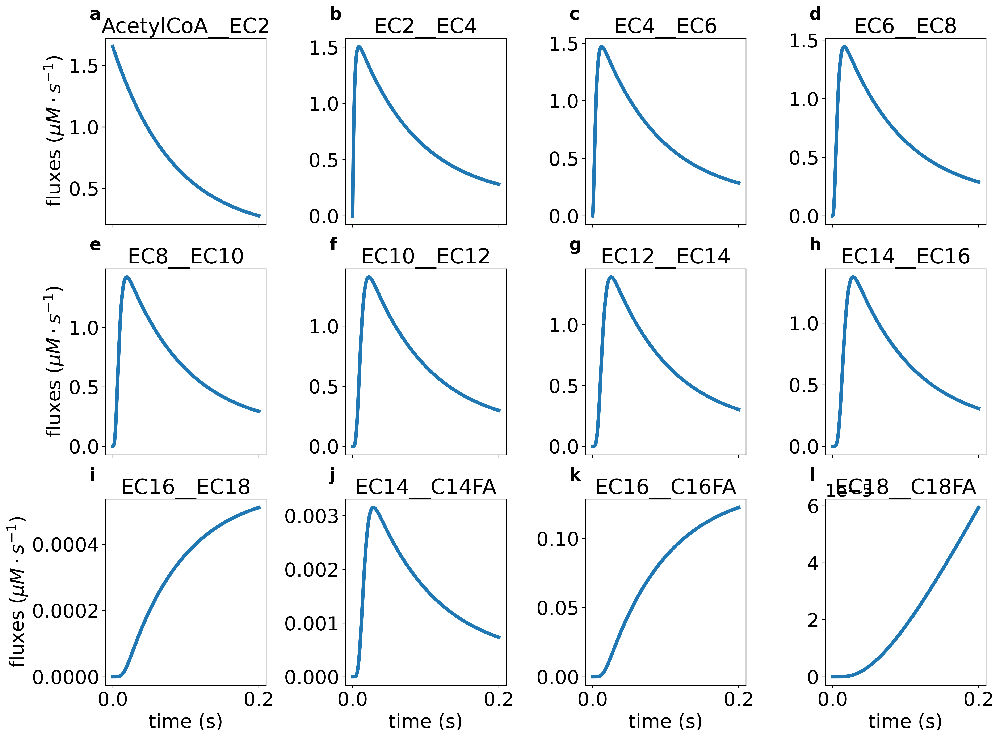

In [13]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
    "EC14__C14FA",
    "EC16__C16FA",
    "EC18__C18FA",
]

fig, axs = plot_fluxes_individually(
    list_fluxes=elongation_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_test_time,
    ncp_list=test_time,
    ncols=4,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


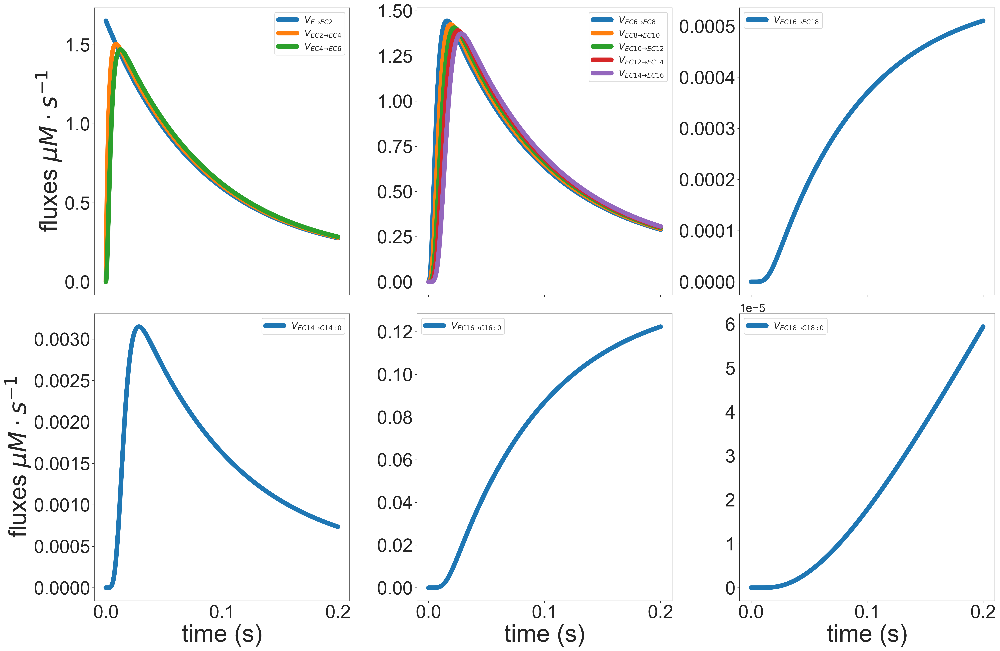

In [14]:
flux_groups = [
    ["AcetylCoA__EC2", "EC2__EC4",
        "EC4__EC6",],
    [
        #"EC2__EC4",
        #"EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        
    ],
    ["EC16__EC18",],
    [
        "EC14__C14FA",],
    ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_test_time,
    ncp_list=test_time,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time (s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =16)
axs[0,1].legend(legend2,   fontsize =16)
axs[0,2].legend(legend3,   fontsize =16)
axs[1,0].legend(legend4, fontsize =16)
axs[1,1].legend(legend5,   fontsize =16)
axs[1,2].legend(legend6,   fontsize =16)
fig.savefig(RESULTS_DIR /"vanilla_fluxes_simple.eps", dpi=300, bbox_inches="tight")



### Time course 

In [15]:
time_course = [
   
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["NADPH"],
   # ["E"],
    #["ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16",],
     ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    ]




colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_test_time,
    ncp_list=test_time,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =16)
    
axs[-1,-3].legend(["C14:0"], fontsize =16)
axs[-1,-2].legend(["C16:0"],   fontsize =16)
axs[-1,-1].legend(["C18:0"],   fontsize =16)

fig.savefig(RESULTS_DIR /"vanilla_time_course_simple.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


## Qualitative dynamics initial phase  

In [16]:
# this is the time to test  the inial phase 


time_linear_phase = [i*0.05 for i in range(0, 101)]
time_linear_phase= np.linspace(0,5,1000)
max_time_linear_phase = time_linear_phase[-1]


### Fluxes

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


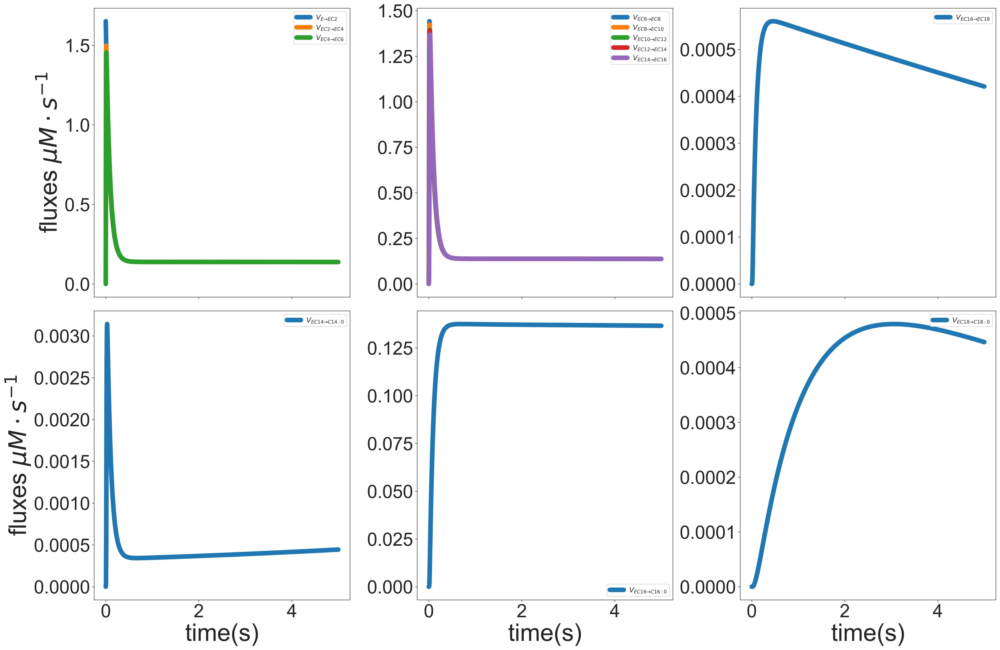

In [17]:
flux_groups = [
    ["AcetylCoA__EC2", "EC2__EC4",
        "EC4__EC6",],
    [
        #"EC2__EC4",
        #"EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        
    ],
    ["EC16__EC18",],
    [
        "EC14__C14FA",],
    ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time= max_time_linear_phase,
    ncp_list= time_linear_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =12)
axs[0,1].legend(legend2,   fontsize =12)
axs[0,2].legend(legend3,   fontsize =12)
axs[1,0].legend(legend4, fontsize =12)
axs[1,1].legend(legend5,   fontsize =12)
axs[1,2].legend(legend6,   fontsize =12)
fig.savefig(RESULTS_DIR /"vanilla_fluxes_initial_simple.eps", dpi=300, bbox_inches="tight")



### Time course 

In [18]:
time_course = [
   
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["NADPH"],
   # ["E"],
    #["ECoA",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
    ["E", "EC16",],
     ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    ]



colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_linear_phase,
    ncp_list=time_linear_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)

axs[-1,-3].legend(["C14:0"], fontsize =16)
axs[-1,-2].legend(["C16:0"],   fontsize =16)
axs[-1,-1].legend(["C18:0"],   fontsize =16)

fig.savefig(RESULTS_DIR /"vanilla_time_course_initial_simple.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


## Long phase 

In [19]:
# this is the time to test  the long


time_long_phase = [i*0.5 for i in range(0, 101)]
time_long_phase = np.linspace(0,50,2000)
max_time_long_phase = time_long_phase[-1]


### fluxes 

IndexError: index 1 is out of bounds for axis 0 with size 1

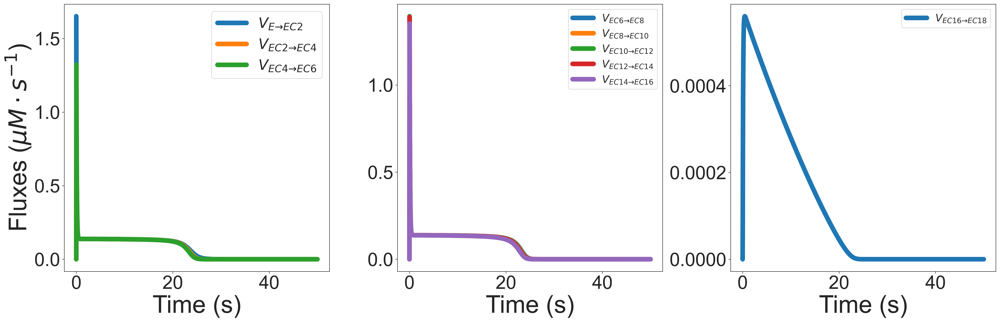

In [20]:
flux_groups = [
    ["AcetylCoA__EC2", "EC2__EC4",
        "EC4__EC6",],
    [
        #"EC2__EC4",
        #"EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        
    ],
    ["EC16__EC18",],
    # [
    #     "EC14__C14FA",],
    # ["EC16__C16FA",],
    #     ["EC18__C18FA",
    # ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time= max_time_long_phase,
    ncp_list= time_long_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Fluxes ($\mu M \cdot s^{-1}$)",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =25)
axs[0,1].legend(legend2,   fontsize =18)
axs[0,2].legend(legend3,   fontsize =18)
axs[1,0].legend(legend4, fontsize =18)
axs[1,1].legend(legend5,   fontsize =18)
axs[1,2].legend(legend6,   fontsize =18)
# for ax in axs.flatten():
#     ax.legend(fontsize =16)
fig.savefig(RESULTS_DIR /"vanilla_eling_fluxes_simple.eps", dpi=300, bbox_inches="tight")



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


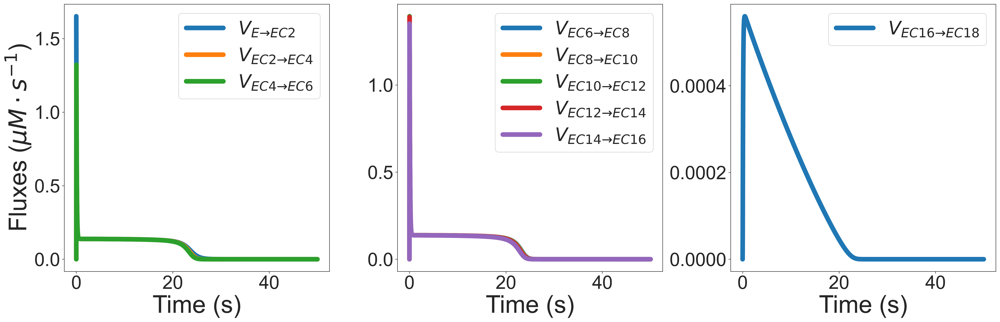

In [21]:
sns.set_style("ticks")

flux_groups = [
    ["AcetylCoA__EC2", "EC2__EC4",
        "EC4__EC6",],
    [
        #"EC2__EC4",
        #"EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        
    ],
    ["EC16__EC18",],
    # [
    #     "EC14__C14FA",],
    # ["EC16__C16FA",],
    #     ["EC18__C18FA",
    # ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time= max_time_long_phase,
    ncp_list= time_long_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Fluxes ($\mu M \cdot s^{-1}$)",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =32)
axs[0,1].legend(legend2,   fontsize =32)
axs[0,2].legend(legend3,   fontsize =32)
# axs[0,0].tick_params(axis='both', which='major', labelsize=30)
# axs[0,1].tick_params(axis='both', which='major', labelsize=30)
# axs[0,2].tick_params(axis='both', which='major', labelsize=30)
# axs[1,0].legend(legend4, fontsize =18)
# axs[1,1].legend(legend5,   fontsize =18)
# axs[1,2].legend(legend6,   fontsize =18)
# for ax in axs.flatten():
#     ax.legend(fontsize =16)

fig.savefig(RESULTS_DIR /"vanilla_elong_fluxes_simple.eps", dpi=300, bbox_inches="tight")



The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


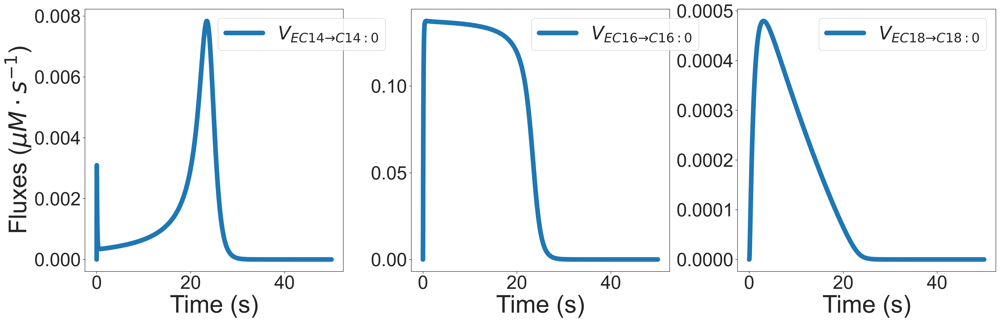

In [22]:
sns.set_style("ticks")

flux_groups = [
    # ["AcetylCoA__EC2", "EC2__EC4",
    #     "EC4__EC6",],
    # [
    #     #"EC2__EC4",
    #     #"EC4__EC6",
    #     "EC6__EC8",
    #     "EC8__EC10",
    #     "EC10__EC12",
    #     "EC12__EC14",
    #     "EC14__EC16",
        
    # ],
    # ["EC16__EC18",],
     ["EC14__C14FA",],
    ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time= max_time_long_phase,
    ncp_list= time_long_phase,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Fluxes ($\mu M \cdot s^{-1}$)",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend4, fontsize =32, loc = "upper right", bbox_to_anchor=(1.2,1))
axs[0,1].legend(legend5,   fontsize =32, loc = "upper right", bbox_to_anchor=(1.15,1))
axs[0,2].legend(legend6,   fontsize =32)
# axs[0,0].tick_params(axis='both', which='major', labelsize=30)
# axs[0,1].tick_params(axis='both', which='major', labelsize=30)
# axs[0,2].tick_params(axis='both', which='major', labelsize=30)
# axs[1,0].legend(legend4, fontsize =18)
# axs[1,1].legend(legend5,   fontsize =18)
# axs[1,2].legend(legend6,   fontsize =18)
# for ax in axs.flatten():
#     ax.legend(fontsize =16)

fig.savefig(RESULTS_DIR /"vanilla_prod_fluxes_simple.eps", dpi=300, bbox_inches="tight")



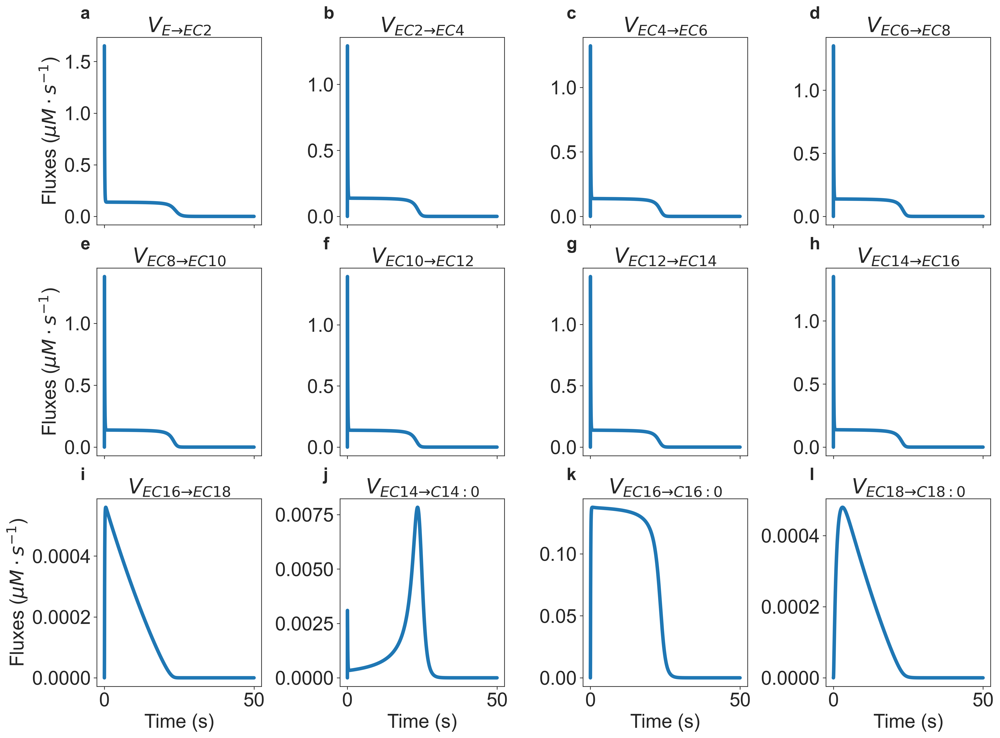

In [23]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
    "EC14__C14FA",
    "EC16__C16FA",
    "EC18__C18FA",
]

elong_legend = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$",
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",
r"$V_{EC16 \to EC18}$",
r"$V_{EC14 \to C14:0}$",
r"$V_{EC16 \to C16:0}$",
r"$V_{EC18 \to C18:0}$"
]

fig, axs = plot_fluxes_individually(
    list_fluxes=elongation_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par_vanilla,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    ncols=4,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="Time (s)",
    ylabel="Fluxes ($\mu M \cdot s^{-1}$)",
)
for i, ax in enumerate(axs.flatten()):
    ax.title.set_text(elong_legend[i])
fig.savefig(RESULTS_DIR /"vanill_all_fluxes_simple.eps", dpi=300, bbox_inches="tight")



### Time course 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


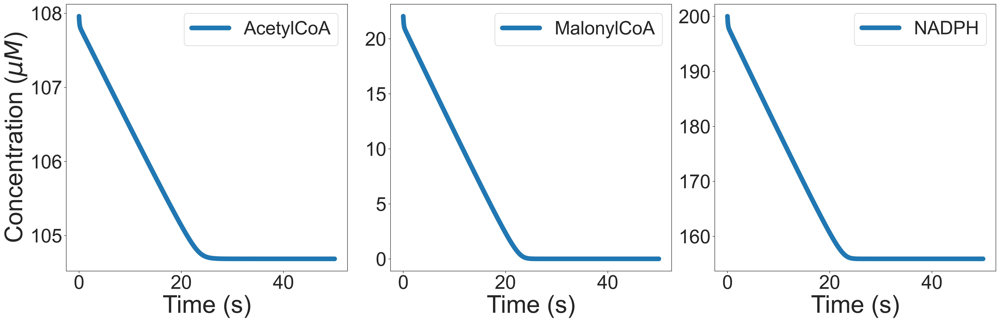

In [24]:
time_course = [
   
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["NADPH"],
   # ["E"],
    #["ECoA",],
    #  ["E", "EC16",],
    # [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
   
    #  ["EC18"],
    #     ["C14FA"],
    #     ["C16FA"],
    #     ["C18FA"],
    # 
    # 
]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =32)
# axs[-1,-3].legend(["C14:0"], fontsize =32)
# axs[-1,-2].legend(["C16:0"],   fontsize =32)
# axs[-1,-1].legend(["C18:0"],   fontsize =32)

fig.savefig(RESULTS_DIR /"vanilla_time_course_sub_simple.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


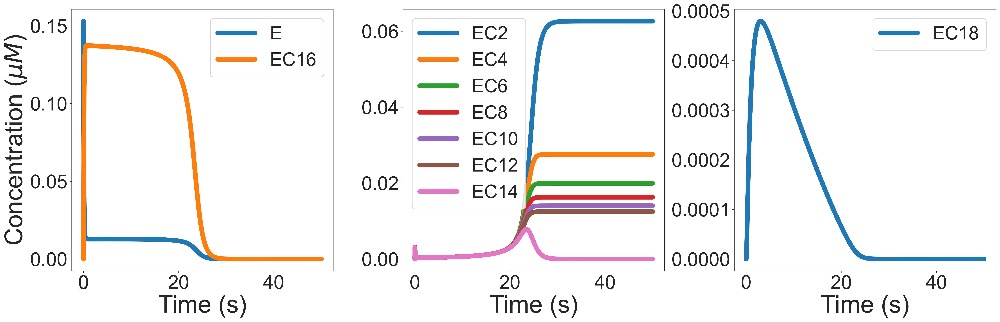

In [25]:
time_course = [
   
    # ["AcetylCoA"],
    # ["MalonylCoA"],
    # ["NADPH"],
#    ["E"],
    # ["ECoA",],
     ["E", "EC16",],
    [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
   
     ["EC18"],
    #     ["C14FA"],
    #     ["C16FA"],
    #     ["C18FA"],
    # 
    # 
]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =32)
# axs[-1,-3].legend(["C14:0"], fontsize =32)
# axs[-1,-2].legend(["C16:0"],   fontsize =32)
# axs[-1,-1].legend(["C18:0"],   fontsize =32)

fig.savefig(RESULTS_DIR /"vanilla_time_course_enz_simple.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


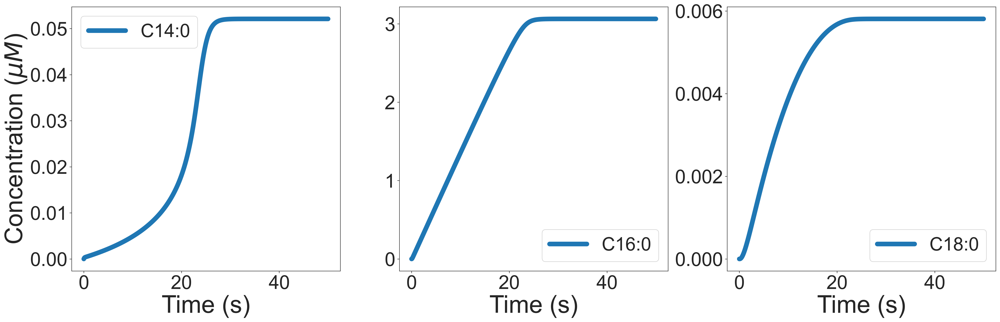

In [26]:
time_course = [
   
    # ["AcetylCoA"],
    # ["MalonylCoA"],
    # ["NADPH"],
#    ["E"],
    # ["ECoA",],
    #  ["E", "EC16",],
    # [ "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14"],
   
    #  ["EC18"],
        ["C14FA"],
        ["C16FA"],
        ["C18FA"],
    # 
    # 
]

colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time_long_phase,
    ncp_list=time_long_phase,
    par=par_vanilla,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="Time (s)",
    ylabel="Concentration ($\mu M$)",
)
for ax in axs.flatten():
    ax.legend(fontsize =32)
axs[-1,-3].legend(["C14:0"], fontsize =32)
axs[-1,-2].legend(["C16:0"],   fontsize =32)
axs[-1,-1].legend(["C18:0"],   fontsize =32)

fig.savefig(RESULTS_DIR /"vanilla_time_course_prod_simple.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


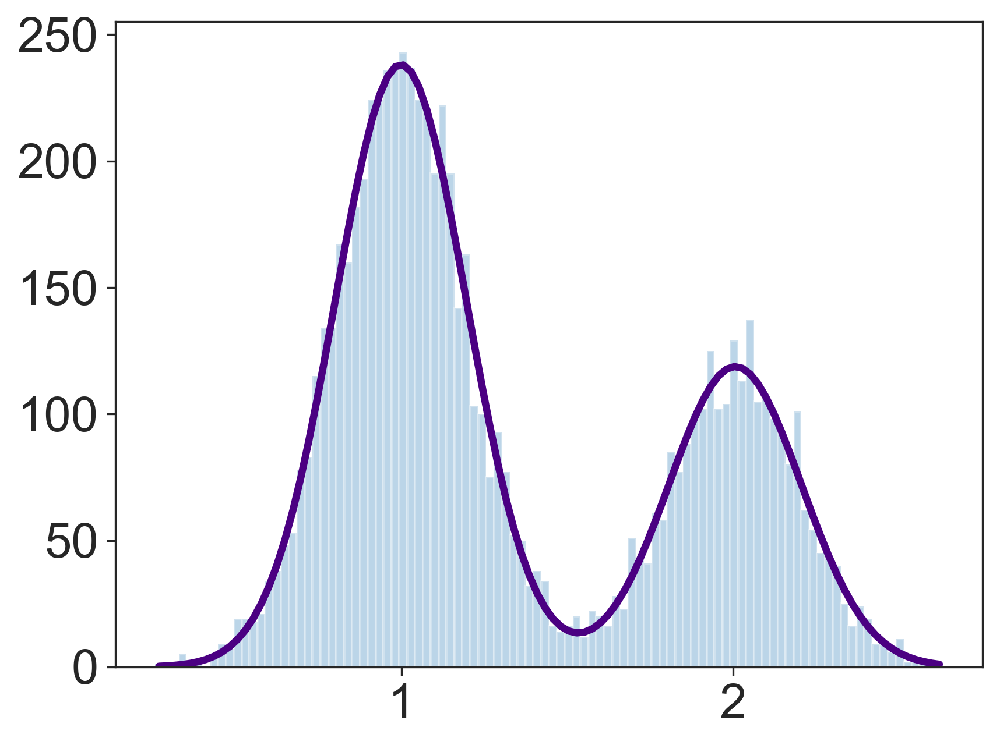

In [27]:
from pylab import *
from scipy.optimize import curve_fit

data=concatenate((normal(1,.2,5000),normal(2,.2,2500)))
y,x,_=hist(data,100,alpha=.3,label='data')

x=(x[1:]+x[:-1])/2 # for len(x)==len(y)

def gauss(x,mu,sigma,A):
    return A*exp(-(x-mu)**2/2/sigma**2)

def bimodal(x,mu1,sigma1,A1,mu2,sigma2,A2):
    return gauss(x,mu1,sigma1,A1)+gauss(x,mu2,sigma2,A2)

expected=(1,.2,250,2,.2,125)
params,cov=curve_fit(bimodal,x,y,expected)
sigma=sqrt(diag(cov))
plot(x,bimodal(x,*params),color='indigo',lw=3,label='model')

plt.savefig(RESULTS_DIR /"bimodal.eps", dpi=300, bbox_inches="tight")

# @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

# Plot the time course


### Plot time course by group


To Estimate the value of parameters that reproduce Topolska and al. data, we first consider the rapid binding given that the subtrates are in excess.Furthermore we consider that production of short and meduim chain fatty acid are negligeable compare to to those of LCFAS as shown by experimental data.On this assumptions, instantaneously the concentration of the total enzyme is sensibly equal to the concentrattion of $EC_{16}$ species. From this concentration of the enzyme we can estimate $k_{d7}$ and $\delta$. For the estimation of the later, we additionnally assume that the flux into $EC_{18}$ are equal to the flux of production of of $C18:0$ FA. The latter assumption makes $K_{d8}$
a minor parameter for the systemunder this assumptions, the rate of release $v_{out\_{C16}}$ of palmitic acid ($C16:0$ )is calculated in the following

$$
v_{out\_{C16}} =  k_{d7} \times EC16
$$,
which implies that
$$

k*{d7} = \dfrac{v*{out\_{C16}}}{EC16 }

$$

From the initial phase data phace data we can infer $v_{out\_{C16}}$  as the concentration $C16$ after 120 secondes  divided by the time (12 0secondes). Hence   $$v_{out\_{C16}} \simeq \dfrac{0.55}{120} =0.0046 \mu M^{-1} s^{-1}$$

 we have $$k_{d7} = 0.03 s^{-1}, \qquad  \delta= 1.17e-06 \mu M ^{-3} s^{-1}$$

Of course the value of beta and Kappa does not matter for the initial phase as we setted  $k_{di}\quad  1\leq i \leq 5$ to 0.  We only have  choose the value of $\beta$ and $\kappa$ fast enough for the rapid binding to be furfilled. but here we give abitrary values to these parameters.
$$


## Remark:

With the abitrary value of $\beta$ and $\kappa$ and the calculation of $k_{d7}$ and $\delta$ we are able to reproduice the initial phase data. We also set $k_{d6}$ and $k_{d8}$.


The objective is to find the impact of the parameters on the initial phase data. One can uncomment the code below to run it  

In [28]:
data_interest = [
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]
par_copy1 = par.copy()
colors = ["#1f77b4", "orange", "green"]

vals = [1e-3, 1e-2, 5e-2, 1e-1, 1, 1e1, 1e2, 1e3]

# for val in vals:
#     par_copy1["beta"] = val
#     fig, axs = multi_plot_time_course(
#         groups=data_interest,legend()
#         func=simulate_time_course,
#         model=system,
#         y0=y0,
#         max_time=max_time1,
#         ncp_list=ncp_list1,
#         par=par_copy1,
#         compounds=compounds,
#         ncols=1,
#         resizer=6,
#         sharey=False,
#         title=f"beta = {val}",
#         xlabel="time(s)",
#         ylabel="concentration ($\mu M$)",
#     )
    # adding data to a particular graph
    # for i in range(3):
    #     axs[0, 0].plot(
    #         time_initial_phase, data_initial_phase[:, i], "o-", color=colors[i]
    #     )
    #     plt.savefig(RESULTS_DIR / f"beta={val}.png")



## Remarks

- From the above plots, we can see that the chosen parameters for initial phase does not capture the transient phase. Furthermore, The value of $k_{d6}$ $k_{d8}$ still have to be adjusted.
- Additionally we can observed that right after the initial phase the production of C14 is exponential, which should not be the case.
- Besides the above remarks, we can see that, here the steady state is reached when the malonyl-CoA is depleted. and this happening too quick.


# Fitting for the three different types of NEFAs

Giving that we calculated the value of some parameters from experimental data, notably the value of $K_{d7}$, $\delta$ under rapid binding considerations(Indeed the substrates are in excess). We now fit others parameters to initial phase data.


# Interpolation to have more points

1. We are not intending to create fake data or add information do experimental data, we only interpolate data points for the stabilty of the fitting.

2. One can keep this step by setting the setting the number of  *number_of_data_points* to the exact number of data points in the original data set.


#


In [29]:
number_of_data_points = 7
time_interp = np.linspace(
    0, time_initial_phase[-1], number_of_data_points
)  # 20 data points between 0 and 120 secs.

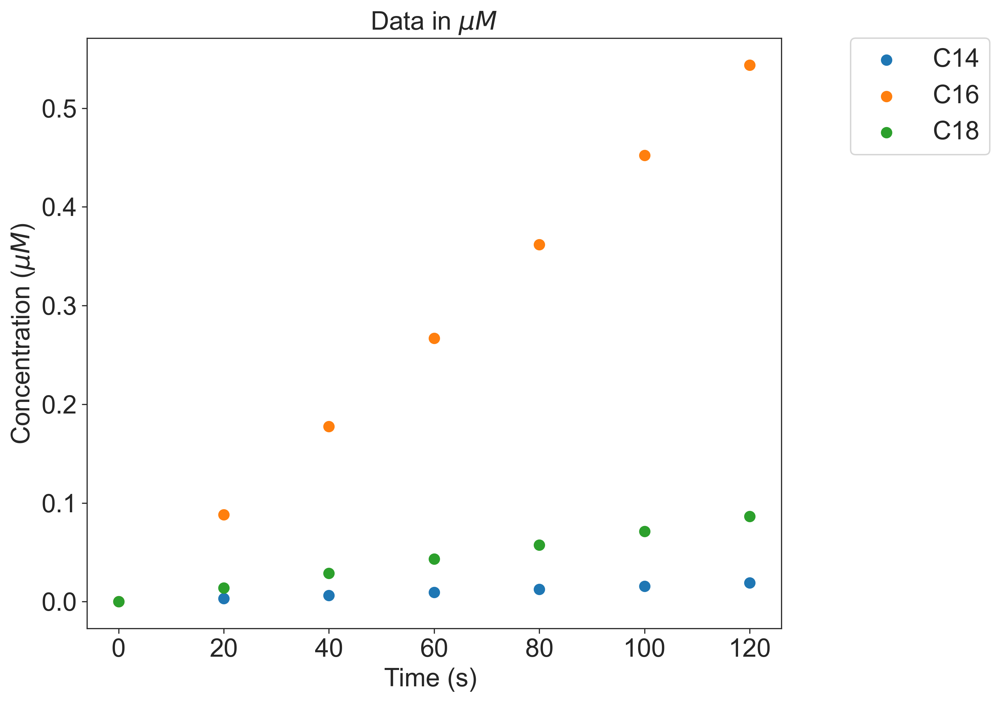

In [30]:
# use of lagrange interporlation to create more data point linearly

lagrange_interpolation_C14 = lagrange(time_initial_phase, data_initial_phase[:, 0])
lagrange_interpolation_C16 = lagrange(time_initial_phase, data_initial_phase[:, 1])
lagrange_interpolation_C18 = lagrange(time_initial_phase, data_initial_phase[:, 2])

C14_data = lagrange_interpolation_C14(time_interp)
C16_data = lagrange_interpolation_C16(time_interp)
C18_data = lagrange_interpolation_C18(time_interp)

data_to_fit = np.array([C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
for i  in range(3):
    plt.scatter(time_interp, data_to_fit[:, i], marker=".", linewidths=5)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concentration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.png", bbox_inches="tight")
plt.show()

In [31]:
# residual function to be passed to lmfit library
# The function *fatty_acid_of_interest* solves the system and only returns  C14, C16 and C18.

# This residual function can oly be used for fitting the inital phase


def residual(parameters, max_time, time, data):
    model = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time, ncp_list=time
    )
    res = (model - data).ravel()

    return res

In [32]:
lower_bounds = [0, 0, 0,0,0] # dimension of the 
upper_bounds = [10, 10, 10, 10, 10]
name_params = [
"beta",
"kappa",
"delta",
"kd6",
#"kd7",
"kd8",
 
    ]
# number of parameter 
n = len(name_params)
# Power of 2 as we are using sobol generator sequence (by setting m=3 the sample size will 2^3 =8)
m =2




list_parameters =[]
list_of_list_values = generate_sobol_sequence(n, m, l_bounds= lower_bounds, u_bounds=upper_bounds).tolist()
list_chisq = []
result_fitting_list =[]
list_of_list_values.pop(0)
list_of_list_values

beta= []
kappa = []
delta = [] 
kd6 = [] 
kd8 = []  

###########################################

#############################################
i=1
for values in list_of_list_values:
    
    parameters_dict= dict(zip(name_params,values))
    #print(parameters_dict)
    par_to_fit = Parameters()
    par_to_fit.add("beta", value= parameters_dict["beta"], min =0, max=1)
    par_to_fit.add("kappa", value=parameters_dict["kappa"], min=0, max =1)
    par_to_fit.add("delta", value=parameters_dict["delta"], min=0, max=1)
    par_to_fit.add("kd6", value=parameters_dict["kd6"], min=0, max =1)
    par_to_fit.add("kd7", value=0.03, vary=False)
    par_to_fit.add("kd8", value=parameters_dict["kd8"],min=0, max =1)
    par_to_fit.add("y0_mal", value=22.04, vary=False)
    
    list_parameters.append(parameters_dict)
    
    result = minimize(
    residual,
    par_to_fit,
    args=(time_interp[-1], time_interp, data_to_fit),
    method="leastsquare",
    )
    list_chisq.append(result.chisqr)
    par_temp = dict(result.params.valuesdict())
    beta.append(par_temp["beta"])
    kappa.append(par_temp["kappa"])
    delta.append(par_temp["delta"])
    kd6.append(par_temp["kd6"])
    kd8.append(par_temp["kd8"])
    print(i)
    i=i+1
    
 

1
2
3


In [33]:
list_of_list_values

[[5.0, 5.0, 5.0, 5.0, 5.0],
 [7.5, 2.5, 2.5, 2.5, 7.5],
 [2.5, 7.5, 7.5, 7.5, 2.5]]

In [34]:
len(list_chisq)

3

In [35]:
list_root_mean_square = list(np.sqrt(np.array(list_chisq)/len(name_params)))
min_chisq = min(list_root_mean_square)
index_min_chisq = list_root_mean_square.index(min_chisq)
print(max(list_root_mean_square))
print(f"The minimal element is {min_chisq}, and it is at index {index_min_chisq}")

parameters_best = dict(zip(name_params, list_of_list_values[index_min_chisq]))
parameters_best

0.004271524596282843
The minimal element is 0.004271524596282843, and it is at index 0


{'beta': 5.0, 'kappa': 5.0, 'delta': 5.0, 'kd6': 5.0, 'kd8': 5.0}

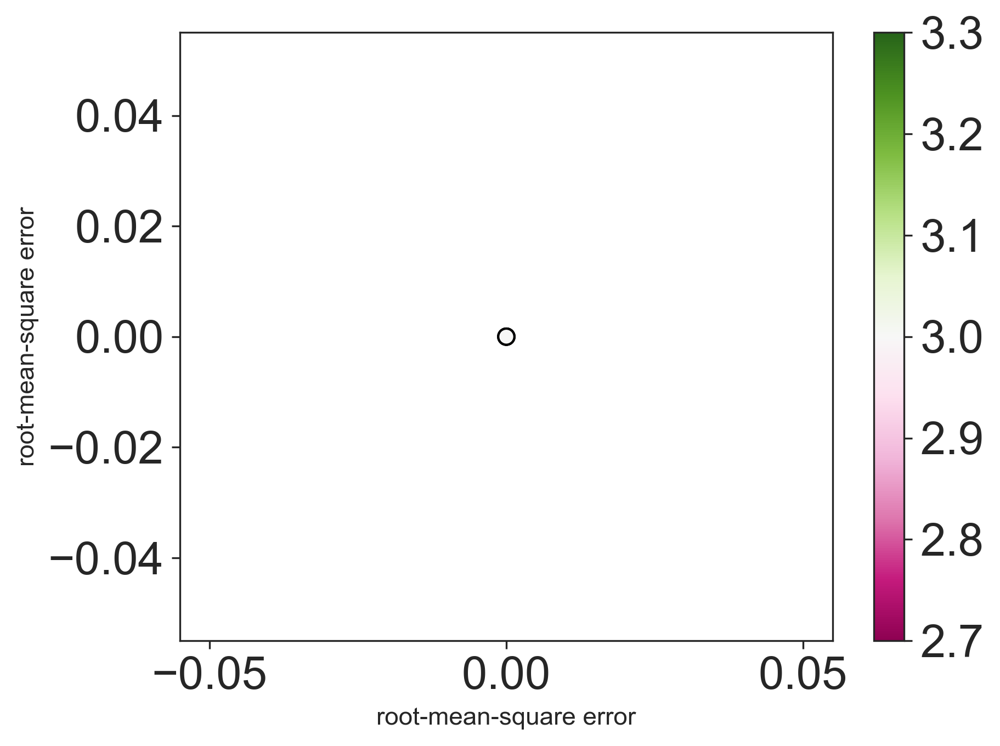

In [36]:
round_list_mean_square = [ round(elem, 2) for elem in list_root_mean_square]

x = round_list_mean_square.copy()
y = round_list_mean_square.copy()

# compute the entry counts
import numpy as np
u,c = np.unique(y, return_counts=True)

# color according to the counts
color = [c[np.where(u==y[i])][0] for i in range(len(y))]

# plot the data (with the function you already used)
plt.scatter(x, y, s=50, c=color, cmap='PiYG', marker='o', edgecolors='black', linewidth=1, alpha=1)
plt.xlabel("root-mean-square error")
plt.ylabel("root-mean-square error")
plt.colorbar()

In [37]:
key_dict_par_list = [r"$\beta$", r"$\kappa$", r"$\delta$", r"$k_{d6}$", r"$k_{d8}$", "RMSE", ]
values_dict_par_list = [beta, kappa, delta, kd6, kd8, round_list_mean_square]

parameter_data_dict = dict(zip(key_dict_par_list, values_dict_par_list))

parameter_chisq_data = pd.DataFrame.from_dict(parameter_data_dict,orient='index').transpose()
parameter_chisq_data 

,$\beta$,$\kappa$,$\delta$,$k_{d6}$,$k_{d8}$,RMSE
0,0.038691,0.012248,0.000001,0.99937,0.665087,0.0
1,0.038691,0.012248,0.000001,0.99937,0.665087,0.0
2,0.038691,0.012248,0.000001,0.99937,0.665087,0.0


In [38]:
parameter_chisq_data ["RMSE"].to_numpy()

array([0., 0., 0.])

In [39]:
selected_data = parameter_chisq_data[parameter_chisq_data ["RMSE"]<0.16]



In [40]:
rc={'axes.labelsize': 34, 'font.size': 36, 'legend.fontsize': 32.0, 'axes.titlesize': 26}
plt.rcParams.update(**rc)
g =sns.pairplot(
                selected_data ,
                hue= "RMSE",
                  palette="tab10",
                plot_kws={"s": 300},
                height=6,
                aspect =1,
                 corner=True,
                 )


g.savefig(RESULTS_DIR /"pairplot_initial_phase.pdf", dpi=300, bbox_inches="tight")

In [41]:
plt.rcParams.update({"figure.dpi": "300"})
plt.rcParams.update(
    {
        "font.family": "serif",  # specify font family here
        "font.serif": ["Times"],  # specify font here
        "font.size": 11,
    }
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]

In [42]:
parameters_best

{'beta': 5.0, 'kappa': 5.0, 'delta': 5.0, 'kd6': 5.0, 'kd8': 5.0}

In [43]:
### Set the parameters name initial value and the min of the parameters

par_to_fit = Parameters()
par_to_fit.add("beta", value=parameters_best["beta"], min=0,max =1)
par_to_fit.add("kappa", value=parameters_best["kappa"], min=0, max =1)
par_to_fit.add(
    "delta",
    value=parameters_best["delta"],
   min =0, max =1
)
par_to_fit.add(
    "kd6",
    value=parameters_best["kd6"],
    min =0,max =10

)
par_to_fit.add("kd7", value=0.03, vary=False)
par_to_fit.add("kd8", value=parameters_best["kd8"], min = 0 , max =10)
par_to_fit.add("y0_mal", value=22.04, vary=False)

In [44]:
# Fitting routine 

result = minimize(
    residual,
    par_to_fit,
    args=(time_interp[-1], time_interp, data_to_fit),
    method="leastsquare",
)
final = data_to_fit + result.residual.reshape(data_to_fit.shape)
final.shape

(7, 3)

In [45]:
report_fit(result)


[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 188
    # data points      = 21
    # variables        = 5
    chi-square         = 4.1316e-05
    reduced chi-square = 2.5822e-06
    Akaike info crit   = -265.914631
    Bayesian info crit = -260.692019
[[Variables]]
    beta:    0.04349157 +/- 0.08531123 (196.16%) (init = 1)
    kappa:   0.11573515 +/- 3.23479974 (2795.00%) (init = 1)
    delta:   1.3022e-06 +/- 3.0201e-08 (2.32%) (init = 1)
    kd6:     9.93610928 +/- 277.951605 (2797.39%) (init = 5)
    kd7:     0.03 (fixed)
    kd8:     0.69973792 +/- 0.89039387 (127.25%) (init = 5)
    y0_mal:  22.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(kappa, kd6)   = 1.000
    C(beta, kd6)    = -0.902
    C(beta, kappa)  = -0.902
    C(delta, kd8)   = -0.852
    C(beta, delta)  = 0.236
    C(beta, kd8)    = -0.218
    C(kappa, kd8)   = -0.216
    C(kd6, kd8)     = -0.216
    C(kappa, delta) = 0.129
    C(delta, kd6)   = 0.129


The step of fitting the $\beta$ and $\kappa$ confirm that we choosed the value in the "right" intervals.


In [46]:
par_initial_phase = dict(result.params.valuesdict())

par_initial_phase

{'beta': 0.04349156946620164,
 'kappa': 0.11573514644949884,
 'delta': 1.3021971136950583e-06,
 'kd6': 9.936109281870747,
 'kd7': 0.03,
 'kd8': 0.6997379178222579,
 'y0_mal': 22.04}

In [47]:
time_initial_phase1 = np.linspace(0, 121, 100) 

intial_phase_nefas = fatty_acid_of_interest(
    system, par_initial_phase, y0, max_time=time_initial_phase1[-1], ncp_list=time_initial_phase1
)


In [48]:
time_long_simulation = np.linspace(0,4801, 200)
all_nefas = total_fatty_acid(system,
                             par_initial_phase,
                             y0, 
                             max_time = time_long_simulation[-1],
                             ncp_list =time_long_simulation
                             )

findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Times
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


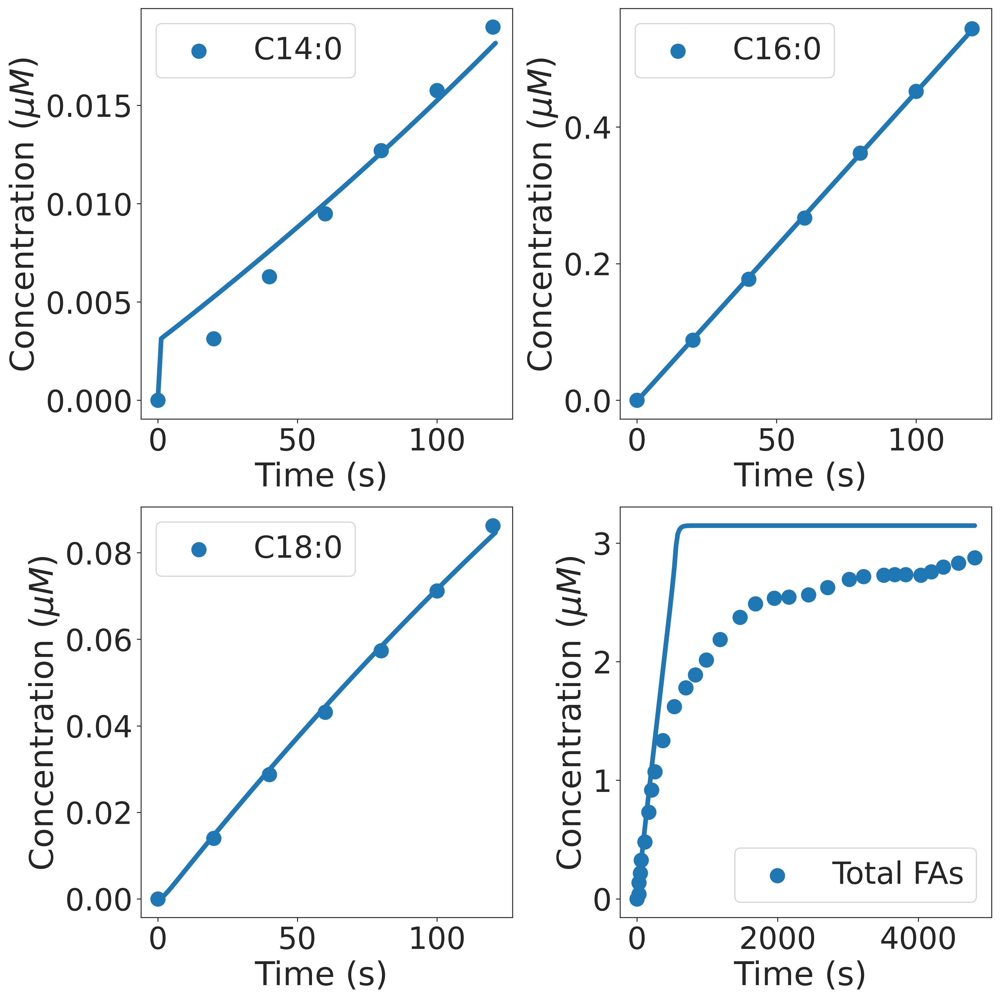

In [49]:
# plotting the results of the simulation
labels = ["C14:0", "C16:0", "C18:0", "Total FAs"]
fig, axs = plt.subplots(2,2, figsize=(12, 12))
ax1,ax2,ax3, ax4 = axs[0,0],axs[0,1], axs[1,0], axs[1,1]

ax1.scatter(time_interp, data_to_fit[:, 0], marker="o", label=labels[0], linewidths=7)
ax1.plot(time_initial_phase1, intial_phase_nefas[:, 0], linewidth=4)
ax2.scatter(time_interp, data_to_fit[:, 1], marker="o", label=labels[1], linewidths=7)
ax2.plot(time_initial_phase1, intial_phase_nefas[:, 1], linewidth=4)
ax3.scatter(time_interp, data_to_fit[:, 2], marker="o", label=labels[2], linewidths=7)
ax3.plot(time_initial_phase1, intial_phase_nefas[:, 2], linewidth=4)
ax4.scatter(time_simulations, total_nefas1, marker="o", label=labels[3], linewidths=7)
ax4.plot(time_long_simulation , all_nefas, linewidth=4)

# plt.plot(time1, final, '-', linewidth=2);
ax1.set_xlabel("Time (s) ", fontsize=28)
ax1.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax2.set_xlabel("Time (s) ", fontsize=28)
ax2.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax3.set_xlabel("Time (s) ", fontsize=28)
ax3.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax4.set_xlabel("Time (s) ", fontsize=28)
ax4.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax1.tick_params(axis="both", labelsize=26)
ax2.tick_params(axis="both", labelsize=26)
ax3.tick_params(axis="both", labelsize=26)
ax4.tick_params(axis="both", labelsize=26)
# plt.yscale("log")
ax1.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax2.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax3.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax4.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)

 
fig.tight_layout()
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR / "initial_phase_simple_fit.eps", bbox_inches="tight")
plt.show()


In [51]:
flux_groups = [
    ["AcetylCoA__EC2",
        "EC2__EC4",
        "EC4__EC6",
    ],
    [
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
    ],
    ["EC16__EC18"],
    [
        "EC14__C14FA",],
        ["EC16__C16FA",],
        ["EC18__C18FA",
    ],
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par_initial_phase,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=3,
    resizer=5,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)
legend1 = [r"$V_{E \to EC2}$",
           r"$V_{EC2 \to EC4}$", 
           r"$V_{EC4 \to EC6}$" ]
legend2 = [
    r"$V_{EC6 \to EC8}$",
    r"$V_{EC8 \to EC10}$", 
    r"$V_{EC10 \to EC12}$", 
    r"$V_{EC12 \to EC14}$", 
    r"$V_{EC14 \to EC16}$",]
legend3 = [  r"$V_{EC16 \to EC18}$", r"$V_{E \to ECoA}$"]
legend4 = [ r"$V_{EC14 \to C14:0}$"]
legend5 = [r"$V_{EC16 \to C16:0}$"]
legend6 = [r"$V_{EC18 \to C18:0}$"]


axs[0,0].legend(legend1, fontsize =12)
axs[0,1].legend(legend2,   fontsize =12)
axs[0,2].legend(legend3,   fontsize =12)
axs[1,0].legend(legend4, fontsize =12)
axs[1,1].legend(legend5,   fontsize =12)
axs[1,2].legend(legend6,   fontsize =12)
#axs[0,0].legend([r"$V_{EC2 \to EC4}$", r"$V_{EC4 \to EC6}$", r"$V_{EC6 \to EC8}$" ],  fontsize =20)
fig.savefig(RESULTS_DIR /"Flux_final_fitting.eps", dpi=300, bbox_inches="tight")

ValueError: Number of rows must be a positive integer, not 2.0

<Figure size 9000x6000 with 0 Axes>

### Simulate for a long run the type of fatty acids produce with the Parameters obtained from fitting of the intial phase

This is to see how the parameters from the initail phase impact the long run simulation


In [52]:


sim_time = np.linspace(0, 4800, 200)
sim_max_time = sim_time[-1]

In [53]:
nefas_fitting = fatty_acid_of_interest(
    system, par_initial_phase, y0, max_time=sim_max_time, ncp_list=sim_time
)


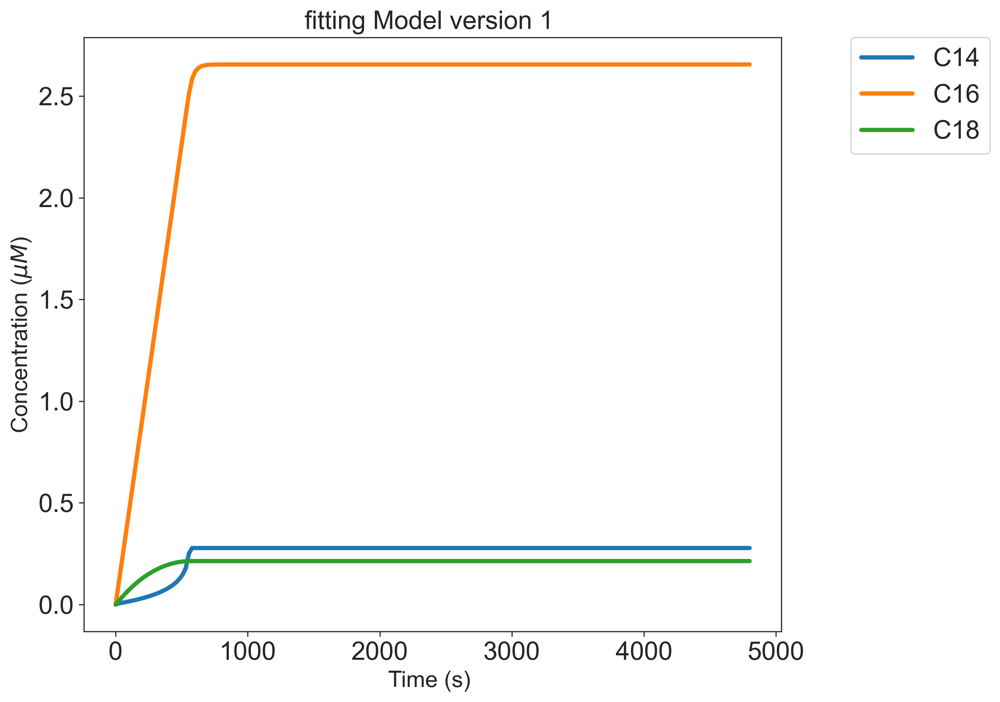

In [54]:
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(3):
    ax.plot(sim_time, nefas_fitting[:, i], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.png", bbox_inches="tight")
plt.show()

The parameters value of the initial phase fails to reproduce the full time course. Furthermore we can see an expected qualitative behavior on the time course of C14:0 and the total production of C14:0 is greater that the one of C18:0.

In conclusion the initial phase parameters fail to capture the transient phase and the steady state dynamics


# Simulate total NEFAs with parameters from initial phase and compare to total NEFAs data

We will keep fixed  the parameters that are less important to the model output, notably $\beta$ and $k_{d8}$. To this parameters, I will assign the value obtained from the from the fitting of the initial phase.




The initial phase parameter is unable to reproduce the total concentration of NEFAs.


## Fitting the total fatty acids for the long run time


In [55]:
def residual_NEFA(parameters, max_time, time, data):
    y0[1] = parameters["y0_mal"].value
    # print(y0)
    model = total_fatty_acid(system, parameters, y0, max_time=max_time, ncp_list=time)
    res = (model - data).ravel()

    return res

### First trial 

To $\beta$ and $k_{d8}$ we assign their values obtained from initial phase fitting 
 

In [56]:
par_total_trial1 = Parameters()
par_total_trial1.add("beta", value=par_initial_phase["beta"], vary =False)
par_total_trial1.add("kappa", value=par_initial_phase["kappa"], min=0)
par_total_trial1.add("delta", value=par_initial_phase["delta"], min =0)
# par_total_trial1.add("kd1", value=0, vary=False)
# par_total_trial1.add("kd2", value=0, vary=False)
# par_total_trial1.add("kd3", value=0, vary=False)
# par_total_trial1.add("kd4", value=0,vary=False)
# par_total_trial1.add("kd5", value= 0,vary=False)
par_total_trial1.add("kd6", value=par_initial_phase["kd6"], min=0)
par_total_trial1.add("kd7", value=0.03, vary=False)
par_total_trial1.add("kd8", value=par_initial_phase["kd8"], vary =False)
par_total_trial1.add("y0_mal", value=22.04, vary=False)

In [57]:
result_trial1 = minimize(
    residual_NEFA,
    par_total_trial1,
    args=(time_simulations[-1], time_simulations, total_nefas1),
    method="leastsq",
)
final1 = total_nefas1 + result_trial1.residual.reshape(total_nefas1.shape)

In [58]:
par_total = dict(result_trial1.params.valuesdict())

par_total

{'beta': 0.04349156946620164,
 'kappa': 58.69818677448726,
 'delta': 9.146991792885473e-07,
 'kd6': 0.002419402461977249,
 'kd7': 0.03,
 'kd8': 0.6997379178222579,
 'y0_mal': 22.04}

In [59]:
time_long_simulation = np.linspace(0,4801, 200)
time_initial_1 =  np.linspace(0,121, 20)

In [60]:
initial_phase_trial = fatty_acid_of_interest(system,
                             par_total,
                             y0, 
                             max_time = time_initial_1[-1],
                             ncp_list =time_initial_1 
                             )

In [61]:
all_nefas = total_fatty_acid(system,
                             par_total,
                             y0, 
                             max_time = time_long_simulation[-1],
                             ncp_list =time_long_simulation
                             )

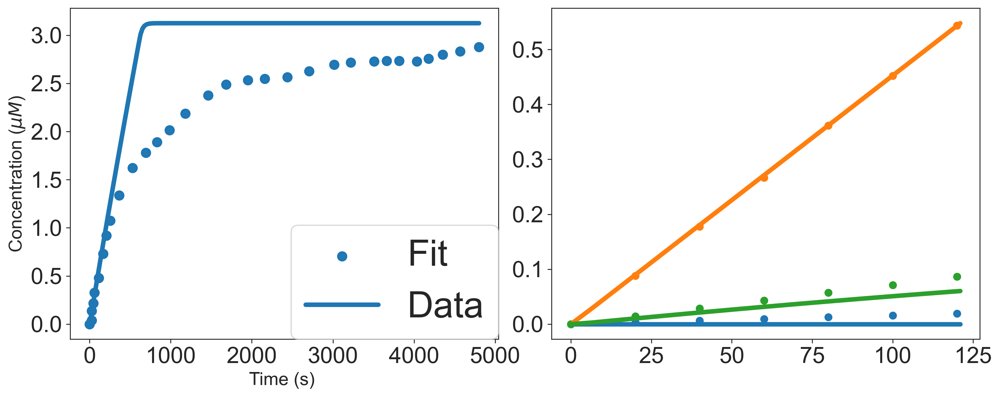

In [62]:
#fig, ax = plt.subplots(figsize=(10, 7))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))

ax1.scatter(time_simulations, total_nefas1, marker=".", linewidths=6)
ax1.plot(time_long_simulation, all_nefas, linewidth=4)

ax2.plot(time_initial_1 ,initial_phase_trial, linewidth=4)
for i in range(3):
    ax2.scatter(time_initial_phase, data_initial_phase[:,i])

# plt.plot(time1, final, '-', linewidth=2);
ax1.set_xlabel("Time (s) ", fontsize=16)
ax1.set_ylabel("Concentration ($\mu M $) ", fontsize=16)
# plt.title("Concentrations over time ", fontsize=18)
# plt.yscale("log")
ax1.legend(
    ["Fit", "Data"],
    loc="best",
    # bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.png", bbox_inches="tight")
plt.show()

In [63]:
report_fit(result_trial1)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 57
    # data points      = 31
    # variables        = 3
    chi-square         = 10.1480535
    reduced chi-square = 0.36243048
    Akaike info crit   = -28.6178639
    Bayesian info crit = -24.3159023
[[Variables]]
    beta:    0.04349157 (fixed)
    kappa:   58.6981868 +/- 23810.5659 (40564.40%) (init = 0.1157351)
    delta:   9.1470e-07 +/- 9.1597e-06 (1001.39%) (init = 1.302197e-06)
    kd6:     0.00241940 +/- 2.41953913 (100005.65%) (init = 9.936109)
    kd7:     0.03 (fixed)
    kd8:     0.6997379 (fixed)
    y0_mal:  22.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(kappa, delta) = -0.974
    C(kappa, kd6)   = 0.810
    C(delta, kd6)   = -0.792


## Conclusion

We need a different strategy to fit the transient and the steady state data. We suggest to explore three strategy

- The solubility
- The sinking enzyme(no longer the conservation relation for the enzymes )
- Or the reversing binding for malanyl-coA


## Release the lower bound of the parameters $\beta$ and $\kappa$

- We now set free the parameter $\beta$ and $\kappa$ and we fit to the long run data.
- We are able to fit the long run data, but the initial phase is not longer reproduced as the value of $\kappa$ ($5\times 10^{-5}$) to small.


In [64]:
par_total_trial2 = Parameters()
par_total_trial2.add("beta", value=1e-01, min=0)
par_total_trial2.add("kappa", value=1e-2, min=0)
par_total_trial2.add("delta", value=1.17e-06, min =0)
# par_total_trial2.add("kd1", value=0, vary=False)
# par_total_trial2.add("kd2", value=0, vary=False)
# par_total_trial2.add("kd3", value=0, vary=False)
# par_total_trial2.add("kd4", value=0,vary=False)
# par_total_trial2.add("kd5", value= 0,vary=False)
par_total_trial2.add("kd6", value=1, min=0)
par_total_trial2.add("kd7", value=0.03, vary=False)
par_total_trial2.add("kd8", value=1, min=0)
par_total_trial2.add("y0_mal", value=22.04, vary=False)

In [65]:
result_trial2 = minimize(
    residual_NEFA,
    par_total_trial2,
    args=(time_simulations[-1], time_simulations, total_nefas1),
    method="leastsq",
)
final2 = total_nefas1 + result_trial2.residual.reshape(total_nefas1.shape)

In [66]:
time_long_simulation = np.linspace(0,4801, 200)

In [67]:
par_total_fit_2 = dict(result_trial2.params.valuesdict())


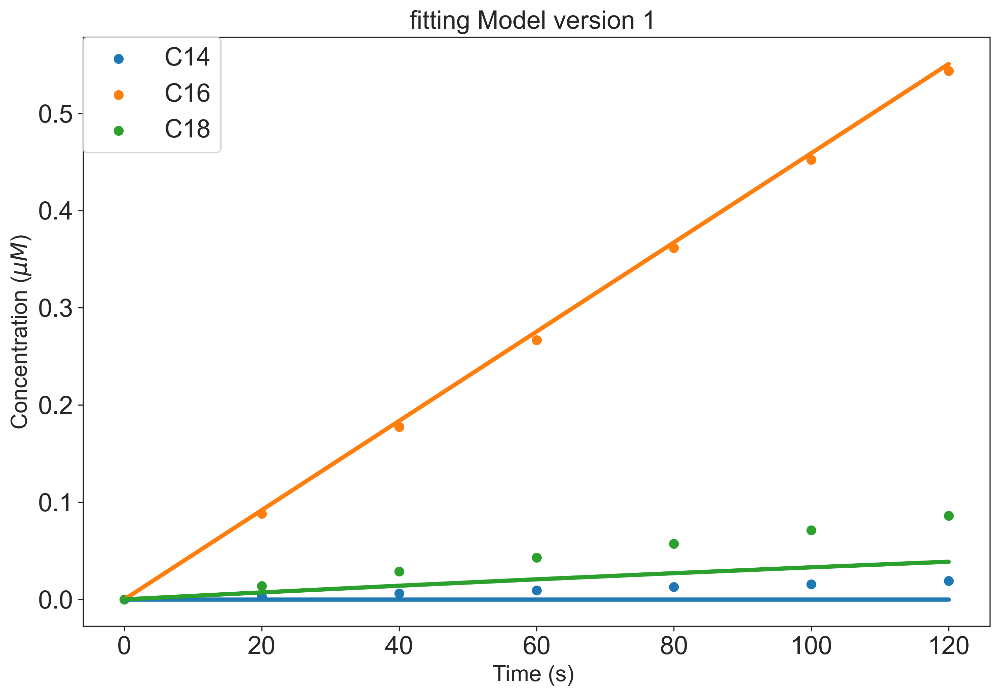

In [68]:
labels =  ["C14", "C16", "C18"]

tot2 = fatty_acid_of_interest(
    system,
    par_total_fit_2,
    y0,
    max_time=time_initial_phase[-1],
    ncp_list=time_initial_phase,
)
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(
        time_initial_phase, data_initial_phase[:, i] , marker="o", label = labels[i]
    )
    ax.plot(time_initial_phase, tot2[:, i], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "Concentrations.png", bbox_inches="tight")
plt.show()

In [69]:
report_fit(result_trial2)


[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 73
    # data points      = 31
    # variables        = 5
    chi-square         = 10.2142144
    reduced chi-square = 0.39285440
    Akaike info crit   = -24.4164135
    Bayesian info crit = -17.2464775
[[Variables]]
    beta:    204.815031 +/- 47562.3014 (23222.08%) (init = 0.1)
    kappa:   15.1020193 +/- 4985.70591 (33013.51%) (init = 0.01)
    delta:   5.7648e-07 +/- 6.9616e-06 (1207.59%) (init = 1.17e-06)
    kd6:     1.3621e-05 +/- 0.00745639 (54740.04%) (init = 1)
    kd7:     0.03 (fixed)
    kd8:     2287.26649 +/- 658584.504 (28793.52%) (init = 1)
    y0_mal:  22.04 (fixed)
[[Correlations]] (unreported correlations are < 0.100)
    C(beta, delta)  = 0.933
    C(kappa, delta) = 0.770
    C(beta, kappa)  = 0.660
    C(kappa, kd6)   = 0.453
    C(delta, kd6)   = 0.391
    C(kd6, kd8)     = 0.378
    C(beta, kd6)    = 0.287
    C(beta, kd8)    = -0.224
    C(delta, kd8)   = -0.175
    C(kappa, kd8)   = 

# Dual fitting

-We now fit the initial phase data and the long run simultaneously by freeing $\beta$, $\kappa$, $k_{d6}$, and $k_{d8}$.


In [70]:
def residual_two(parameters, max_time1, time1, data1, max_time2, time2, data2):
    y0[1] = parameters["y0_mal"].value
    # print(y0)
    model1 = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time1, ncp_list=time1
    )
    model2 = total_fatty_acid(
        system, parameters, y0, max_time=max_time2, ncp_list=time2
    )
    res1 = (model1 - data1).ravel()
    res2 = (model2 - data2).ravel()

    return np.concatenate((res1, res2))






# Run for several initial conditions 

In [71]:
lower_bounds = [0, 0, 0] # dimension of the 
upper_bounds = [100, 1, 100]
name_params = [
#"beta",
"kappa",
"delta",
"kd6",
#"kd7",
#"kd8",
# "kf_CoA",
# "kb_CoA", 
    ]
# number of parameter 
n = len(name_params)
# Power of 2 as we are using sobol generator sequence (by setting m=3 the sample size will 2^3 =8)
m =4




list_parameters =[]
list_of_list_values = generate_sobol_sequence(n, m, l_bounds= lower_bounds, u_bounds=upper_bounds).tolist()
list_chisq = []
result_fitting_list =[]
list_of_list_values 

[[0.0, 0.0, 0.0],
 [50.0, 0.5, 50.0],
 [75.0, 0.25, 25.0],
 [25.0, 0.75, 75.0],
 [37.5, 0.375, 62.5],
 [87.5, 0.875, 12.5],
 [62.5, 0.125, 87.5],
 [12.5, 0.625, 37.5],
 [18.75, 0.3125, 93.75],
 [68.75, 0.8125, 43.75],
 [93.75, 0.0625, 68.75],
 [43.75, 0.5625, 18.75],
 [31.25, 0.1875, 31.25],
 [81.25, 0.6875, 81.25],
 [56.25, 0.4375, 6.25],
 [6.25, 0.9375, 56.25]]

In [72]:
for values in list_of_list_values:
    parameters_dict= dict(zip(name_params,values))
    #print(parameters_dict)
    par_dual = Parameters()
    par_dual.add("beta", value= par_initial_phase["beta"], vary = False)
    par_dual.add("kappa", value=parameters_dict["kappa"], min=0, max =1)
    par_dual.add("delta", value=parameters_dict["delta"], min=0, max =1)
    # par_dual.add("kd1", value=0, vary=False)
    # par_dual.add("kd2", value=0, vary=False)
    # par_dual.add("kd3", value=0, vary=False)
    # par_dual.add("kd4", value=0,vary=False)
    # par_dual.add("kd5", value= 0.0,vary=False)
    par_dual.add("kd6", value=parameters_dict["kd6"], min=0)
    par_dual.add("kd7", value=0.03, vary=False)
    par_dual.add("kd8", value=par_initial_phase["kd8"],vary=False)
    par_dual.add("y0_mal", value=22.04, vary=False)
    
    list_parameters.append(parameters_dict)
    
    result_two = minimize(
    residual_two,
    par_dual,
    args=(
        time_interp[-1],
        time_interp,
        data_to_fit,
        time_simulations[-1],
        time_simulations,
        total_nefas1,
    ),
    method="leastsquare",
)
    list_chisq.append(result_two.chisqr)
 

In [73]:
list_root_mean_square = list(np.sqrt(np.array(list_chisq)/len(name_params)))
min_chisq = min(list_root_mean_square)
index_min_chisq = list_root_mean_square.index(min_chisq)
print(max(list_root_mean_square))
print(f"The minimal element is {min_chisq}, and it is at index {index_min_chisq}")

parameters_best = dict(zip(name_params, list_of_list_values[index_min_chisq]))
parameters_best

6.785914277852135
The minimal element is 0.6036220073146246, and it is at index 6


{'kappa': 62.5, 'delta': 0.125, 'kd6': 87.5}

In [74]:
list_root_mean_square


[6.785914277852135,
 0.6036220073909992,
 0.6037513830167132,
 1.8361945692389186,
 5.252175386082562,
 1.8539966586822971,
 0.6036220073146246,
 1.8344396332092239,
 5.251830019017132,
 0.6549634307807012,
 0.6036220235402594,
 0.6426303987663273,
 1.8392438320897244,
 5.25224904859102,
 1.825469008386317,
 1.3655035016656654]

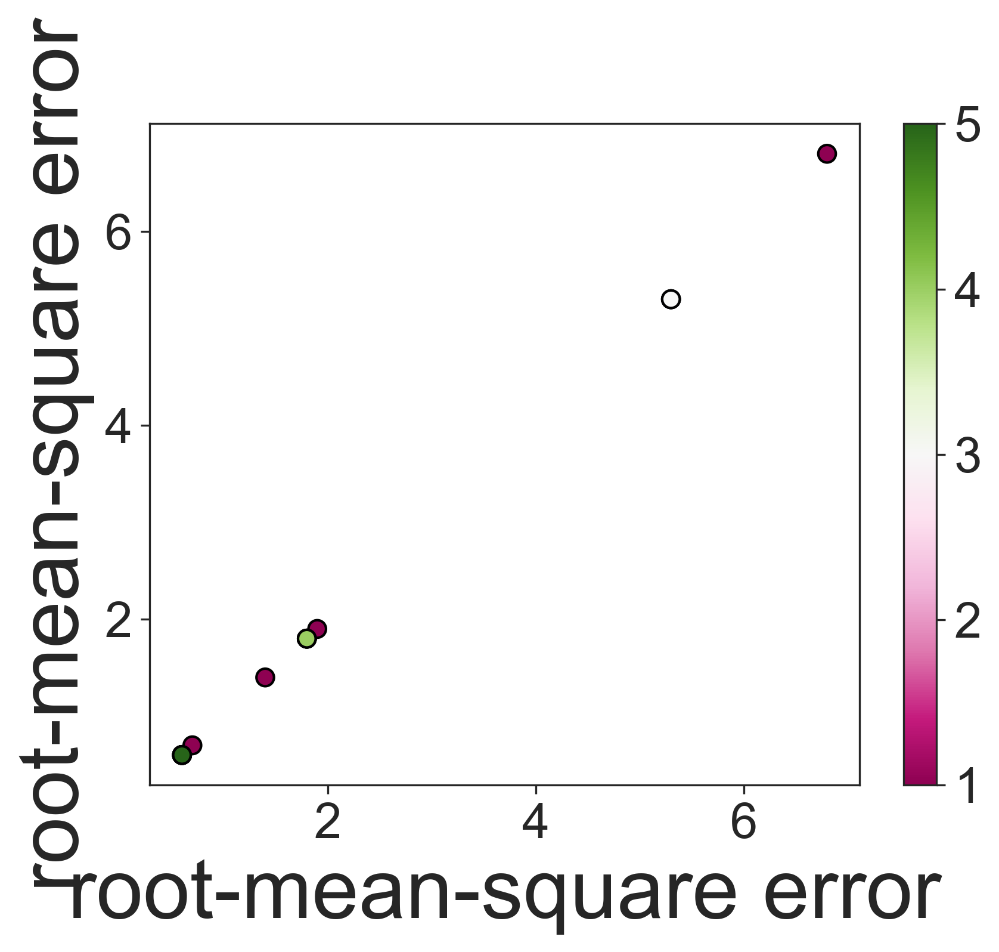

In [75]:
round_list_mean_square = [ round(elem, 1) for elem in list_root_mean_square]

x = round_list_mean_square.copy()
y = round_list_mean_square.copy()

# compute the entry counts
import numpy as np
u,c = np.unique(y, return_counts=True)

# color according to the counts
color = [c[np.where(u==y[i])][0] for i in range(len(y))]

# plot the data (with the function you already used)
plt.scatter(x, y, s=50, c=color, cmap='PiYG', marker='o', edgecolors='black', linewidth=1, alpha=1)
plt.xlabel("root-mean-square error")
plt.ylabel("root-mean-square error")
plt.colorbar()

In [76]:
par_dual = Parameters()
par_dual.add("beta", value = par_initial_phase["beta"], vary=False)
par_dual.add("kappa", value = parameters_best["kappa"], min=0, max =1)
par_dual.add("delta", value = parameters_best["delta"], min=0, max =1)
# par_dual.add("kd1", value=0, vary=False)
# par_dual.add("kd2", value=0, vary=False)
# par_dual.add("kd3", value=0, vary=False)
# par_dual.add("kd4", value=0,vary=False)
# par_dual.add("kd5", value= 0.0,vary=False)
par_dual.add("kd6", value=parameters_best["kd6"], min=0)
par_dual.add("kd7", value=0.03, vary=False)
par_dual.add("kd8", value=par_initial_phase["kd8"], min=0)
par_dual.add("y0_mal", value=22.04, vary=False)


In [77]:
result_two = minimize(
    residual_two,
    par_dual,
    args=(
        time_interp[-1],
        time_interp,
        data_to_fit,
        time_simulations[-1],
        time_simulations,
        total_nefas1,
    ),
    method="leastsquare",
)
# final_two = data2 + result.residual.reshape(data2.shape)
# final_two.shape

In [78]:
par_fitting_two = dict(result_two.params.valuesdict())
par_fitting_two


{'beta': 0.04349156946620164,
 'kappa': 0.2679551546261507,
 'delta': 0.9192814371543465,
 'kd6': 0.00047724577810193125,
 'kd7': 0.03,
 'kd8': 0.016178865022180355,
 'y0_mal': 22.04}

In [79]:
print('-------------------------------')
print('Parameter    Value       Stderr')
for name, param in result_two.params.items():
    print(f'{name:7s} {param.value:11.5f} {param.stderr:11.5f}')

-------------------------------
Parameter    Value       Stderr
beta        0.04349     0.00000
kappa       0.26796    13.81717
delta       0.91928   816.30030
kd6         0.00048     0.06192
kd7         0.03000     0.00000
kd8         0.01618     0.00289
y0_mal     22.04000     0.00000


In [80]:
initial_phase_trial2 = fatty_acid_of_interest(system,
                             par_fitting_two,
                             y0, 
                             max_time = time_initial_1[-1],
                             ncp_list =time_initial_1 
                             )

In [81]:
time_long_simulation = np.linspace(0,4801, 200)
all_nefas2 = total_fatty_acid(system,
                             par_fitting_two,
                             y0, 
                             max_time = time_long_simulation[-1],
                             ncp_list =time_long_simulation
                             )

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


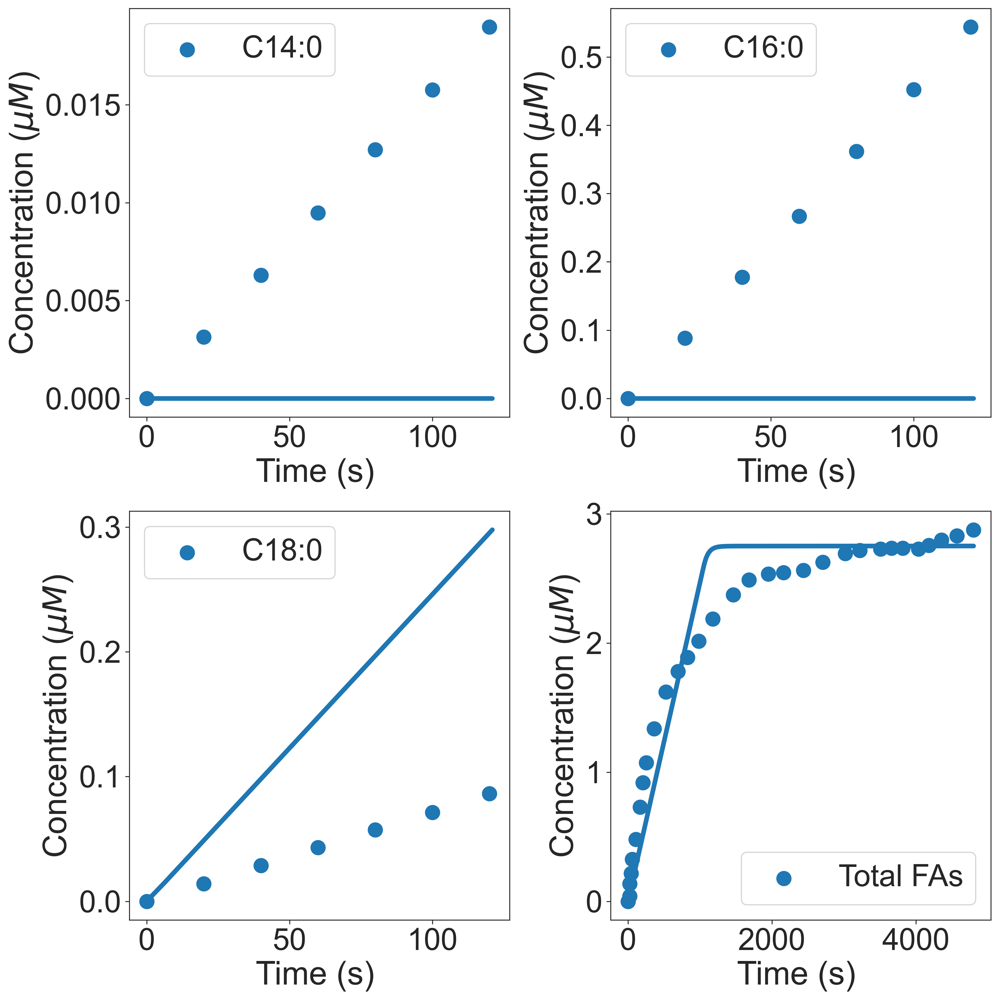

In [82]:
# plotting the results of the simulation
labels = ["C14:0", "C16:0", "C18:0", "Total FAs"]
fig, axs = plt.subplots(2,2, figsize=(12, 12))
ax1,ax2,ax3, ax4 = axs[0,0],axs[0,1], axs[1,0], axs[1,1]

ax1.scatter(time_interp, data_to_fit[:, 0], marker="o", label=labels[0], linewidths=7)
ax1.plot(time_initial_1, initial_phase_trial2[:, 0], linewidth=4)
ax2.scatter(time_interp, data_to_fit[:, 1], marker="o", label=labels[1], linewidths=7)
ax2.plot(time_initial_1,initial_phase_trial2[:, 1], linewidth=4)
ax3.scatter(time_interp, data_to_fit[:, 2], marker="o", label=labels[2], linewidths=7)
ax3.plot(time_initial_1, initial_phase_trial2[:, 2], linewidth=4)
ax4.scatter(time_simulations, total_nefas1, marker="o", label=labels[3], linewidths=7)
ax4.plot(time_long_simulation , all_nefas2, linewidth=4)

# plt.plot(time1, final, '-', linewidth=2);
ax1.set_xlabel("Time (s) ", fontsize=28)
ax1.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax2.set_xlabel("Time (s) ", fontsize=28)
ax2.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax3.set_xlabel("Time (s) ", fontsize=28)
ax3.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax4.set_xlabel("Time (s) ", fontsize=28)
ax4.set_ylabel("Concentration ($\mu M$) ", fontsize=28)
ax1.tick_params(axis="both", labelsize=26)
ax2.tick_params(axis="both", labelsize=26)
ax3.tick_params(axis="both", labelsize=26)
ax4.tick_params(axis="both", labelsize=26)
# plt.yscale("log")
ax1.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax2.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax3.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
ax4.legend(
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    #borderaxespad=0,
    fontsize=26,
)
fig.tight_layout()
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR / "dual_phase_simple_fit.eps", bbox_inches="tight")
plt.show()


In [83]:
time_long_simulation = np.linspace(0,4801, 200)

In [84]:
simulated_nefas = total_fatty_acid(
    system,
    par=par_fitting_two,
    y0=y0,
    max_time=time_long_simulation[-1],
    ncp_list=time_long_simulation,
)


### check the parameters on initial phase data


In [85]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par_fitting_two,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="Chilperic",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_fatty_acid(
    system, par_fitting_two, y0, max_time=time_simulations, ncp_list=ncp_list2
)

for i in range(3):
    axs[2, i].scatter(time_initial_phase, data_initial_phase[:, i], marker=".", linewidths =5)

ValueError: Number of rows must be a positive integer, not 1.0

<Figure size 7200x2400 with 0 Axes>

### check the parameters on long run


In [86]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fitting_two,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_fatty_acid(
    system, par_fitting_two, y0, max_time=time_simulations, ncp_list=ncp_list2
)

axs[1, 2].plot(time_simulations, total_nefas1, "o-", color=colors[i])
axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
axs[1, 2].legend(
    ["Data total NEFAs", "simulated"],
)
fig.patch.set_alpha(0.0)  # to make the axis transparent
plt.savefig(RESULTS_DIR / "long_sim.eps", bbox_inches="tight")

ValueError: Number of rows must be a positive integer, not 1.0

<Figure size 7200x2400 with 0 Axes>

# Conclusion

- We can fit simultaneously the initial phase and the long run data to the model. Which allows us to conclude that the model is missing some features.

-The strategy to correct the transient and the steady state data. We suggest to explore three strategy

- The sinking enzyme( the enzyme is denaturated over time )
- The CoA inhibition
- The competition between the acetyl-CoA and the malonyl-CoA

For the either strategy we will keep the rapid binding assumptio given that the chanelling is to make the reaction relatively faster.


In [ ]:
plt.rcParams.update({"figure.dpi": "300"})
plt.rcParams.update(
    {
        "font.family": "serif",  # specify font family here
        "font.serif": ["Times"],  # specify font here
        "font.size": 11,
    }
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]

# Sensitivity analaysis


In [ ]:
time_sens = np.linspace(0, 500, 2000)
max_time_sens= time_sens[-1]

In [ ]:

sample_size =2**11
problem = {
    "num_vars": 6,
    "names": [
        "beta",
        "kappa",
        "delta",
        # "kd1",
        # "kd2",
        # "kd3",
        # "kd4",
        # "kd5",
        "kd6",
        "kd7",
        "kd8",
    ],
    "bounds": [
        [0, 1e1],
        [0, 1e1],
        [0, 1e1],
        [0, 1e1],
        [0, 1e1],
        [0, 1e1],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
        # [0,1e1],
    ],
}


param_values = saltelli.sample(problem, sample_size , calc_second_order=True)


def func(values: list[float], names: list[str]):
    
    param_dict=dict(zip(names, values))
    expr = (
            fatty_acid_of_interest(
                system,
               param_dict,
                y0,
                max_time= max_time_sens,
                ncp_list= time_sens,
            )
        )
    # normalize the data
    norm1 = expr  / np.linalg.norm(expr )
    return norm1.mean(axis=0)


with ProcessPoolExecutor() as executor:
    names = problem["names"]
    y = list(executor.map(func, param_values, it.repeat(names)))
    # print(y)

Y = np.array(y)

In [ ]:
# paramt = dict(zip(problem["names"], param_values[0]))
# print(paramt)

# func(paramt.values(), par.keys())
# # for i in range(len(param_values)):
# #     func(param_values[i], problem["names"])

In [ ]:
label_S1_ST = (
    r"$\beta$",
    r"$\kappa$",
    r"$\delta$",
    r"$k_{d6}$",
    r"$k_{d7}$",
    r"$k_{d8}$",
)

label_S1_ST

('$\\beta$', '$\\kappa$', '$\\delta$', '$k_{d6}$', '$k_{d7}$', '$k_{d8}$')

In [ ]:
label_list = [
    r"$\beta$",
    r"$\kappa$",
    r"$\delta$",
    r"$k_{d6}$",
    r"$k_{d7}$",
    r"$k_{d8}$",
]

In [ ]:
label_S2 = (
    r"($\beta$, $\kappa$)",
    r"($\beta$, $\delta$)",
    r"($\beta$, $k_{d6}$)",
    r"($\beta$, $k_{d7}$)",
    r"($\beta$, $k_{d8}$)",
    r"($\kappa$, $\delta$)",
    r"($\kappa$, $k_{d6}$)",
    r"($\kappa$, $k_{d7}$)",
    r"($\kappa$, $k_{d8}$)",
    r"($\delta$, $k_{d6}$)",
    r"($\delta$, $k_{d7}$)",
    r"($\delta$, $k_{d8}$)",
    r"($k_{d6}$, $k_{d7}$)",
    r"($k_{d6}$, $k_{d8}$)",
    r"($k_{d7}$, $k_{d8}$)",
)

In [ ]:
Si_C14 = sobol.analyze(problem, Y[:, 0], print_to_console=False)
Si_C16 = sobol.analyze(problem, Y[:, 1], print_to_console=False)
Si_C18 = sobol.analyze(problem, Y[:, 2], print_to_console=False)


In [ ]:
Saltelli_TC14, Saltelli_1stC14, Saltelli_2stC14 = Si_C14.to_df()
Saltelli_TC16, Saltelli_1stC16, Saltelli_2stC16 = Si_C16.to_df()
Saltelli_TC18, Saltelli_1stC18, Saltelli_2stC18 = Si_C18.to_df()

In [ ]:
dfS1 = pd.concat(
    {
        "C14": Saltelli_1stC14,
        "C16": Saltelli_1stC16,
        "C18": Saltelli_1stC18,
    }
)
dfS2 = pd.concat(
    {
        "C14": Saltelli_2stC14,
        "C16": Saltelli_2stC16,
        "C18": Saltelli_2stC18,
    }
)
dfST = pd.concat(
    {
        "C14": Saltelli_TC14,
        "C16": Saltelli_TC16,
        "C18": Saltelli_TC18,
    }
)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


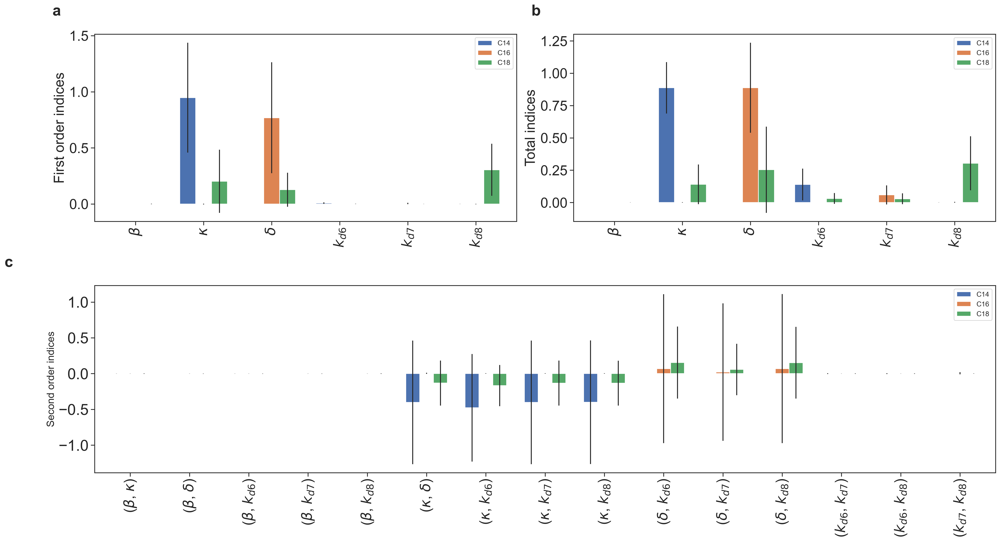

In [ ]:
sns.set()
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(22, 12))
gs = gridspec.GridSpec(2, 2)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

dfS1["S1"].unstack().T.plot(
    kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1, width=0.7
)
dfST["ST"].unstack().T.plot(
    kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax2, width=0.7
)
dfS2["S2"].unstack().T.plot(
    kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3, width=0.7
)

ax1.set_ylabel("First order indices", fontsize=22)
ax2.set_ylabel("Total indices", fontsize=22)
ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=22)
ax2.tick_params(axis="x", labelsize=22)
ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=22)
ax2.tick_params(axis="y", labelsize=22)
ax3.tick_params(axis="y", labelsize=24)

ax1.text(
    -0.1,
    1.1,
    string.ascii_lowercase[0],
    transform=ax1.transAxes,
    size=24,
    weight="bold",
)
ax2.text(
    -0.1,
    1.1,
    string.ascii_lowercase[1],
    transform=ax2.transAxes,
    size=24,
    weight="bold",
)
ax3.text(
    -0.1,
    1.1,
    string.ascii_lowercase[2],
    transform=ax3.transAxes,
    size=24,
    weight="bold",
)
ax1.set_xticklabels(label_S1_ST, fontsize=22)
ax2.set_xticklabels(label_S1_ST, fontsize=22)
ax3.set_xticklabels(label_S2, fontsize=22)


fig.patch.set_alpha(0.0)

plt.tight_layout()
fig.savefig(RESULTS_DIR / "sobol_examp1.eps", dpi=300, bbox_inches="tight")

## Only the total index and the first index 

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


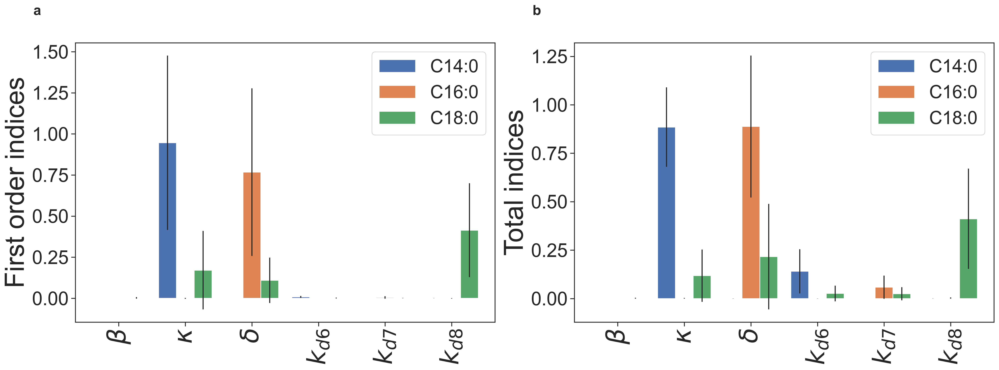

In [ ]:
sns.set()
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(20, 7.5))
gs = gridspec.GridSpec(1, 2)


ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
#ax3 = fig.add_subplot(gs[1, :])

dfS1["S1"].unstack().T.plot(
    kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1, width=0.8, 
)
dfST["ST"].unstack().T.plot(
    kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax2, width=0.8
)
dfS2["S2"].unstack().T.plot(
    kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3, width=0.8
)

ax1.set_ylabel("First order indices", fontsize=38)
ax2.set_ylabel("Total indices", fontsize=38)
#ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=22)
ax2.tick_params(axis="x", labelsize=22)
#ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=27)
ax2.tick_params(axis="y", labelsize=27)
#ax3.tick_params(axis="y", labelsize=24)

ax1.text(
    -0.1,
    1.1,
    string.ascii_lowercase[0],
    transform=ax1.transAxes,
    size=20,
    weight="bold",
)
ax2.text(
    -0.1,
    1.1,
    string.ascii_lowercase[1],
    transform=ax2.transAxes,
    size=20,
    weight="bold",
)
# ax3.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[2],
#     transform=ax3.transAxes,
#     size=24,
#     weight="bold",
# )
ax1.set_xticklabels(label_S1_ST, fontsize=36)
ax2.set_xticklabels(label_S1_ST, fontsize =36)
#ax3.set_xticklabels(label_S2, fontsize=22)

ax1.legend(["C14:0", "C16:0", "C18:0"],loc='best',
           prop={'size': 26}
           )
ax2.legend(["C14:0", "C16:0", "C18:0"],loc='best', 
           prop={'size': 26}
           )

fig.patch.set_alpha(0.0)



plt.tight_layout()
fig.savefig(RESULTS_DIR / "sensitivity_analysis_simple_model.eps", dpi=300, bbox_inches="tight")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


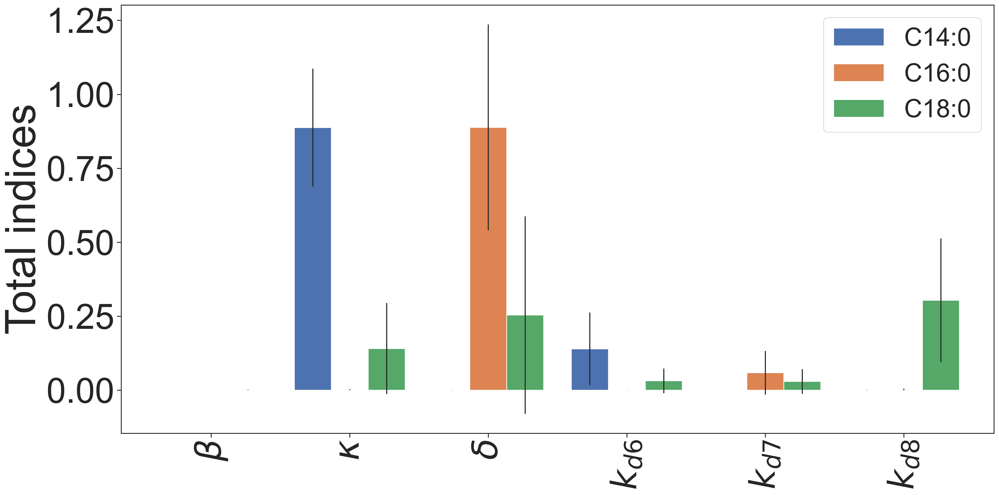

In [ ]:
sns.set()
sns.set_style("ticks")

fig = plt.figure(tight_layout=True, figsize=(20, 10))
gs = gridspec.GridSpec(1, 1)


ax1 = fig.add_subplot(gs[0, 0])
#ax2 = fig.add_subplot(gs[0, 1])
#ax3 = fig.add_subplot(gs[1, :])

# dfS1["S1"].unstack().T.plot(
#     kind="bar", yerr=dfS1["S1_conf"].unstack().T, ax=ax1, width=0.8, 
# )
dfST["ST"].unstack().T.plot(
    kind="bar", yerr=dfST["ST_conf"].unstack().T, ax=ax1, width=0.8
)
dfS2["S2"].unstack().T.plot(
    kind="bar", yerr=dfS2["S2_conf"].unstack().T, ax=ax3, width=0.8
)

ax1.set_ylabel("Total indices", fontsize=60)
# ax2.set_ylabel("Total indices", fontsize=38)
#ax3.set_ylabel("Second order indices", fontsize=16)


ax1.tick_params(axis="x", labelsize=32)
# ax2.tick_params(axis="x", labelsize=22)
#ax3.tick_params(axis="x", labelsize=22)

ax1.tick_params(axis="y", labelsize=50)
# ax2.tick_params(axis="y", labelsize=27)
#ax3.tick_params(axis="y", labelsize=24)

# ax1.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[0],
#     transform=ax1.transAxes,
#     size=20,
#     weight="bold",
# )
# ax2.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[1],
#     transform=ax2.transAxes,
#     size=20,
#     weight="bold",
# )
# ax3.text(
#     -0.1,
#     1.1,
#     string.ascii_lowercase[2],
#     transform=ax3.transAxes,
#     size=24,
#     weight="bold",
# )
ax1.set_xticklabels(label_S1_ST, fontsize=50)
# ax2.set_xticklabels(label_S1_ST, fontsize =36)
#ax3.set_xticklabels(label_S2, fontsize=22)

ax1.legend(["C14:0", "C16:0", "C18:0"],loc='best',
           prop={'size': 36}
           )
# ax2.legend(["C14:0", "C16:0", "C18:0"],loc='best', 
#            prop={'size': 26}
#            )

fig.patch.set_alpha(0.0)



plt.tight_layout()
fig.savefig(RESULTS_DIR / "sensitivity_analysis_simple_modelST.eps", dpi=300, bbox_inches="tight")

# Heat map of everything together

Second order index represented with the heat map.


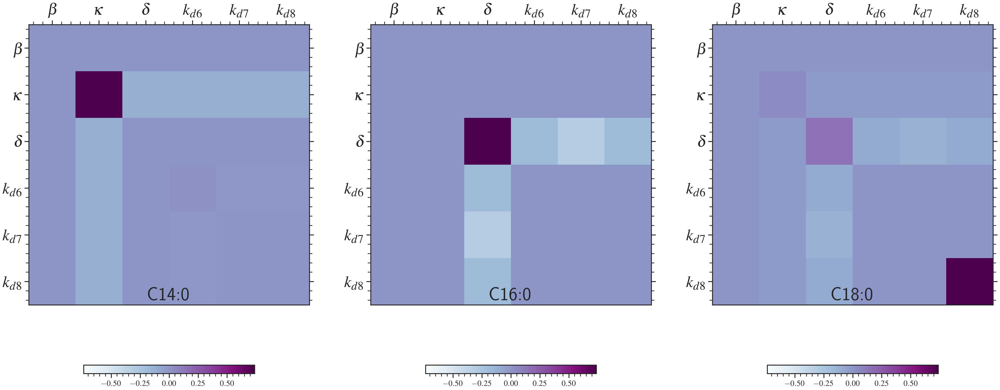

In [ ]:
import matplotlib.ticker as mticker

n_params = problem["num_vars"]
comp_matrix_C14 = np.ndarray(shape=(n_params, n_params))
comp_matrix_C16 = np.ndarray(shape=(n_params, n_params))
comp_matrix_C18 = np.ndarray(shape=(n_params, n_params))
for j in range(n_params):
    for i in range(n_params):
        if i == j:
            comp_matrix_C14[i, j] = Si_C14["S1"][i]
            comp_matrix_C16[i, j] = Si_C16["S1"][i]
            comp_matrix_C18[i, j] = Si_C18["S1"][i]
        else:
            comp_matrix_C14[i, j] = Si_C14["S2"][i, j]
            comp_matrix_C14[j, i] = Si_C14["S2"][i, j]
            comp_matrix_C16[i, j] = Si_C16["S2"][i, j]
            comp_matrix_C16[j, i] = Si_C16["S2"][i, j]
            comp_matrix_C18[i, j] = Si_C18["S2"][i, j]
            comp_matrix_C18[j, i] = Si_C18["S2"][i, j]

# print comp_matrix

# define labels for figure: phi = dip, d = dip direction, s = slip, subscript = fault event
label_names = [
    "",
    r"$\beta$",
    r"$\kappa$",
    r"$\delta$",
    r"$k_{d6}$",
    r"$k_{d7}$",
    r"$k_{d8}$",
]

# Create figure
fig, axs = plt.subplots(1, 3, figsize=(24, 10))

im_c14 = axs[0].imshow(
    comp_matrix_C14,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C14)),
    vmin=-np.max(np.abs(comp_matrix_C14)),
)
im_c16 = axs[1].imshow(
    comp_matrix_C16,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C16)),
    vmin=-np.max(np.abs(comp_matrix_C16)),
)
im_c18 = axs[2].imshow(
    comp_matrix_C18,
    interpolation="nearest",
    cmap="BuPu",
    vmax=np.max(np.abs(comp_matrix_C18)),
    vmin=-np.max(np.abs(comp_matrix_C18)),
)

positions= [-1,0, 1,2,3,4,5]
axs[0].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[0].yaxis.set_major_locator(mticker.FixedLocator(positions))


axs[1].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[1].yaxis.set_major_locator(mticker.FixedLocator(positions))

axs[2].xaxis.set_major_locator(mticker.FixedLocator(positions))
axs[2].yaxis.set_major_locator(mticker.FixedLocator(positions))

axs[0].yaxis.set_ticks_position("both")
axs[0].xaxis.set_ticks_position("top")

axs[0].set_xticklabels(label_names, fontsize =22)
axs[0].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[0], shrink=0.6, location="bottom")

axs[1].yaxis.set_ticks_position("both")
axs[1].xaxis.set_ticks_position("top")
# axs[1].set_xticks([i for i in range(9)])
# axs[1].set_yticks([i for i in range(9)])
axs[1].set_xticklabels(label_names, fontsize =22)
axs[1].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[1], shrink=0.6, location="bottom")

axs[2].yaxis.set_ticks_position("both")
axs[2].xaxis.set_ticks_position("top")

axs[2].set_xticklabels(label_names, fontsize =22)
axs[2].set_yticklabels(label_names, fontsize =22)
fig.colorbar(im_c14, ax=axs[2], shrink=0.6, location="bottom")
#axs[-1, -1].axis("off")

axs[0].set_title("C14:0", fontsize =26, y=-0.0)
axs[1].set_title("C16:0", fontsize =26, y=-0.0)
axs[2].set_title("C18:0", fontsize =26,  y=-0.0)

# ax.set_xlabel("Parameter Sensitivities")

# fig.colorbar(im_c14)
fig.patch.set_alpha(0.0)
fig.savefig(RESULTS_DIR / "heat_map_SA_simple_model.eps", dpi=300, bbox_inches="tight")

In [ ]:
example = {
    "num_vars": 3,
    "names": [
        "x",
        "y",
        "y"
    ],
    "bounds": [
        [0, 1],
        [0, 1],
        [0, 1],
    ]

}

In [ ]:
n =512

In [ ]:
example_sample = saltelli.sample(example,n, calc_second_order=True, skip_values=4096)

In [ ]:
example_sample.shape


(4096, 3)

In [ ]:

df = pd.DataFrame(example_sample, columns = ['x','y','z'])
df

,x,y,z
0,0.000366,0.470581,0.835815
1,0.620483,0.470581,0.835815
2,0.000366,0.164917,0.835815
3,0.000366,0.470581,0.542847
4,0.000366,0.164917,0.542847
...,...,...,...
4091,0.002319,0.972534,0.415894
4092,0.002319,0.440308,0.415894
4093,0.274780,0.972534,0.415894
4094,0.274780,0.440308,0.740112


In [ ]:
m2 =4096
x1,y1,z1 = df["x"], df["y"], df["z"]

x2, y2,z2 = sample = np.random.random(m2), np.random.random(m2), np.random.random(m2)

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

/tmp/ipykernel_100781/3971460241.py:3: MatplotlibDeprecationWarning: Axes3D(fig) adding itself to the figure is deprecated since 3.4. Pass the keyword argument auto_add_to_figure=False and use fig.add_axes(ax) to suppress this warning. The default value of auto_add_to_figure will change to False in mpl3.5 and True values will no longer work in 3.6.  This is consistent with other Axes classes.
  ax = Axes3D(fig, auto_add_to_figure=True,)
/tmp/ipykernel_100781/3971460241.py:11: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


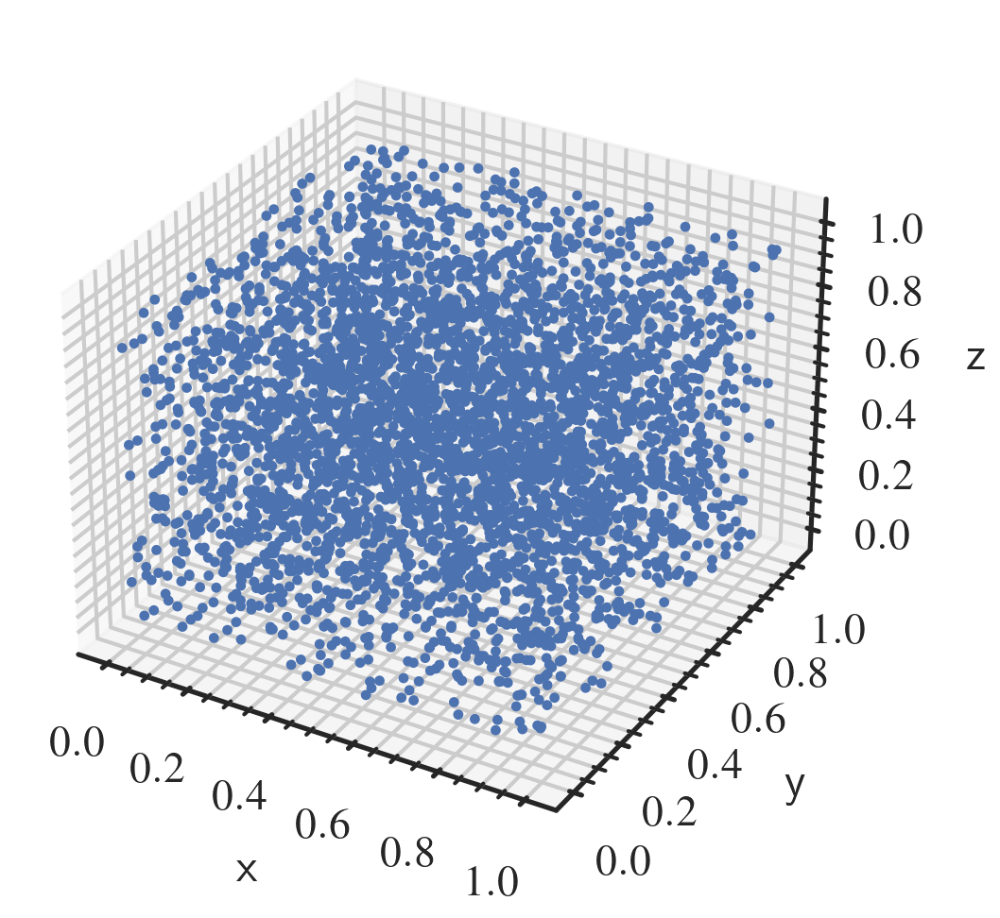

In [ ]:
cmap = ListedColormap(sns.color_palette("husl", 256).as_hex())
fig = plt.figure(figsize=(3,3))
ax = Axes3D(fig, auto_add_to_figure=True,)
fig.add_axes(ax)

ax.scatter3D(x1, y1, z1, s=10, marker='.', cmap=cmap, alpha=1)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
fig.patch.set_alpha(0.0)
plt.tight_layout()
plt.show()

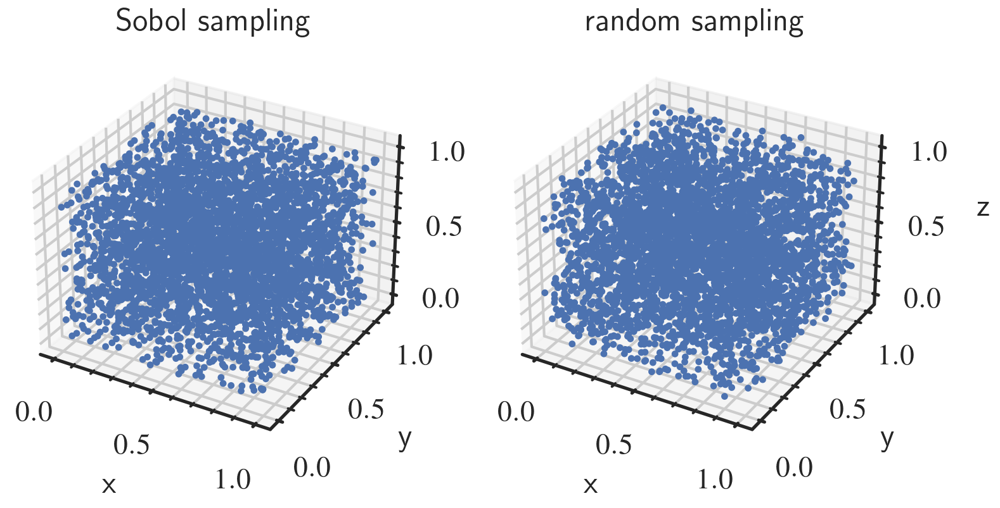

In [ ]:
cmap = ListedColormap(sns.color_palette("husl", 256).as_hex())
fig = plt.figure(figsize=plt.figaspect(0.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')

ax.scatter3D(x1, y1, z1, s=10, marker='.', cmap=cmap, alpha=1)
# ax.scatter3D(x2, y2, z2, s=10, marker='.', cmap=cmap, alpha=1)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Sobol sampling')
ax = fig.add_subplot(1, 2, 2, projection='3d')
#ax = Axes3D(fig, auto_add_to_figure=True,)
fig.add_axes(ax)

ax.scatter3D(x2, y2, z2, s=10, marker='.', cmap=cmap, alpha=1)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('random sampling')
fig.patch.set_alpha(0.0)
plt.tight_layout()
plt.show()

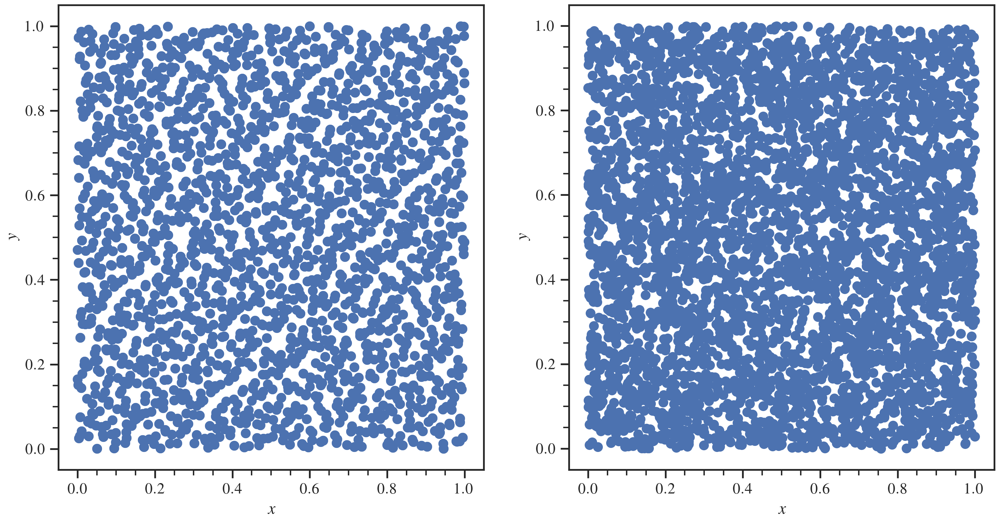

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,6))
ax1.scatter(x1,y1)
ax2.scatter(x2,y2)
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')
ax2.set_xlabel('$x$')
ax2.set_ylabel('$y$')
fig.patch.set_alpha(0.0)